# HyperDiag: A Hypergraph Attention Network for Symptom-Based Differential Diagnosis under a Leakage-Free Evaluation Protocol

*Thesis pre-defence: computational report (fully reproducible notebook)*

---
### Abstract
**Background.** Symptom-checker datasets are widely used to train diagnostic classifiers, but they are usually evaluated with
random train/test splits, and the higher-order (set-level) structure of symptoms is seldom modelled.
**Methods.** We audit the Kaggle *Diseases and Symptoms* dataset (246,945 cases, 773 diseases, 377 binary symptoms), derive its
Bayes-optimal top-k ceiling, and propose a symptom-pattern-grouped split with zero train/test leakage. We introduce **HyperDiag**,
a hypergraph attention network with disease hyperedges, NPMI co-occurrence hyperedges, dual-level (node ↔ hyperedge) attention,
query-aware hyperedge attention, disease-hyperedge prototype scoring and query-adaptive hyperedge-likelihood evidence.
HyperDiag is compared with seven baselines (Naive Bayes, Random Forest, Logistic Regression, MLP, GCN, GAT, HGNN) on more than 20
evaluation metrics, with a statistical analysis (McNemar with Holm correction, Friedman/Nemenyi, Wilcoxon signed-rank with effect sizes,
paired bootstrap confidence intervals), robustness, rare-disease, ablation, calibration and attention-faithfulness analyses.
**Results** are produced by the cells below and summarised in §14.

**Keywords:** hypergraph neural network · attention · differential diagnosis · data leakage · symptom checker · interpretability

---
### Report structure
| § | Section | § | Section |
|---|---|---|---|
| 1 | Computational environment and reproducibility | 8 | Results: main comparison and comprehensive metrics |
| 2 | Materials: dataset acquisition | 9 | Statistical analysis |
| 3 | Exploratory data audit (C1) | 10 | Robustness to partial symptom sets |
| 4 | Preprocessing and leakage-free protocol | 11 | Rare versus frequent diseases |
| 5 | Methods I: hypergraph construction (Algorithm 1) | 12 | Ablation study |
| 6 | Methods II: models (Algorithm 2) and training (Algorithm 3) | 13 | Interpretability and explanation faithfulness |
| 7 | Experiments | 14 | Summary of findings, discussion and conclusion |

**Contributions.** **C1** data audit, leakage quantification and Bayes ceiling; **C2** the HyperDiag model;
**C3** a statistically rigorous, clinically motivated multi-metric evaluation. Figures are saved to `results/figures/`, tables to `results/*.csv`.

## ⚙️ User settings: the only cell you need to edit
Set `DATASET` to **any one** of the following, then choose **Run All**:
* a Kaggle dataset link, e.g. `https://www.kaggle.com/datasets/dhivyeshrk/diseases-and-symptoms-dataset`
  (on Kaggle you can also attach it via **+ Add Input**; the notebook finds it under `/kaggle/input` automatically)
* a Kaggle slug, e.g. `dhivyeshrk/diseases-and-symptoms-dataset`
* a direct link to a `.csv` or `.zip` file
* a local path to the CSV file or to the folder that contains it

`FAST = True` runs a quick check (4 epochs, 1 seed, about 10 min). `FAST = False` runs the full experiment
(20 epochs, 3 seeds; about 80 min on CPU, much faster on a Kaggle GPU).

In [1]:
DATASET = "https://www.kaggle.com/datasets/dhivyeshrk/diseases-and-symptoms-dataset"
FAST = False

## 1. Computational Environment and Reproducibility
All random seeds, hyper-parameters and library versions are fixed here. A shared figure style and one fixed colour per model are used in every figure.

In [2]:
import os, json, time, math, random, warnings, platform
from collections import Counter, defaultdict
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import sparse
from scipy.stats import spearmanr, chi2
from sklearn.model_selection import train_test_split
from sklearn.metrics import (f1_score, precision_recall_fscore_support, cohen_kappa_score, matthews_corrcoef)
from sklearn.manifold import TSNE
from scipy.stats import friedmanchisquare, wilcoxon, rankdata
import networkx as nx
from sklearn.naive_bayes import BernoulliNB
from sklearn.ensemble import RandomForestClassifier

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30)
# ---- publication figure style -------------------------------------------------
sns.set_theme(style="ticks", context="paper")
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 300, "savefig.bbox": "tight",
    "font.family": "DejaVu Sans", "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "axes.labelsize": 9, "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8, "legend.frameon": False,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#52514e", "axes.linewidth": 0.8,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "lines.linewidth": 2.0, "lines.markersize": 5, "text.color": "#0b0b0b", "axes.labelcolor": "#0b0b0b",
})
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#9a9993"
# one fixed colour per model (validated categorical palette, fixed order, never cycled)
MODEL_ORDER = ["Naive Bayes (Bernoulli)", "Random Forest", "LogReg (softmax)", "MLP", "GCN (pairwise)",
               "GAT (pairwise)", "HGNN (hypergraph, no attention)", "HyperDiag (ours)"]
_CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
COL = dict(zip(MODEL_ORDER, _CAT))
SHORT = dict(zip(MODEL_ORDER, ["NB", "RF", "LogReg", "MLP", "GCN", "GAT", "HGNN", "HyperDiag"]))
SEQ, DIV = "Blues", "RdBu_r"          # sequential (magnitude) and diverging (signed) colormaps

def show(x):
    """Display a table nicely in Jupyter, or print it in a plain Python run."""
    try: display(x)
    except NameError: print(x)

def fmt_p(p):
    """Format a p-value; values below double precision are reported as < 1e-300."""
    return "< 1e-300" if p is None or p < 1e-300 else f"{p:.1e}"

def panel(ax, letter):
    ax.text(-0.12, 1.06, letter, transform=ax.transAxes, fontsize=12, fontweight="bold", va="bottom", ha="left")

FAST = os.environ.get("HYPERDIAG_FAST", "1" if FAST else "0") == "1"   # set in the user-settings cell
CFG = dict(
    min_cases=5,          # diseases with fewer unique cases cannot be split train/val/test reliably
    test_frac=0.20, val_frac=0.10,
    dim=128, heads=4, layers=2, dropout=0.2,
    batch=1024, lr=2e-3, weight_decay=1e-4,
    epochs=4 if FAST else 20, patience=100,
    seeds=[0] if FAST else [0, 1, 2],
    sym_dropout=float(os.environ.get("SYMDROP", 0.5)),  # max per-case symptom-masking rate (all neural models)
    label_smoothing=0.05,
    cw_power=0.5,         # class weight ~ n_c^-0.5 (imbalance handling)
    dis_thresh=0.02,      # P(s|d) threshold for disease-hyperedge membership
    cooc_k=4, cooc_min_npmi=0.10, cooc_min_count=10,
    graph_k=10,           # neighbours per symptom in the pairwise graph (GCN/GAT)
    keep_ratios=[1.0, 0.8, 0.6, 0.4, 0.2],
)
ROOT = os.path.abspath(".")
RES = os.path.join(ROOT, "results"); FIG = os.path.join(RES, "figures")
os.makedirs(FIG, exist_ok=True)
torch.set_num_threads(max(1, os.cpu_count() or 1))
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)

def savefig(name):
    plt.savefig(os.path.join(FIG, name)); plt.show(); plt.close("all")

print("python", platform.python_version(), "| torch", torch.__version__, "| device", DEV, "| threads", torch.get_num_threads())
print("FAST mode" if FAST else "FULL mode", json.dumps(CFG))

python 3.13.18 | torch 2.15.0+cu132 | device cpu | threads 4
FULL mode {"min_cases": 5, "test_frac": 0.2, "val_frac": 0.1, "dim": 128, "heads": 4, "layers": 2, "dropout": 0.2, "batch": 1024, "lr": 0.002, "weight_decay": 0.0001, "epochs": 20, "patience": 100, "seeds": [0, 1, 2], "sym_dropout": 0.5, "label_smoothing": 0.05, "cw_power": 0.5, "dis_thresh": 0.02, "cooc_k": 4, "cooc_min_npmi": 0.1, "cooc_min_count": 10, "graph_k": 10, "keep_ratios": [1.0, 0.8, 0.6, 0.4, 0.2]}


## 2. Materials: Dataset Acquisition
`DATASET` (from the user-settings cell) is resolved automatically: local path, then `/kaggle/input`, then a download
(with `kagglehub` for Kaggle links, or a plain HTTP download for direct links).

In [3]:
import glob, re, zipfile, shutil, urllib.request
DATASET = os.environ.get("HYPERDIAG_DATA", DATASET)
CSV_NAME = "Final_Augmented_dataset_Diseases_and_Symptoms.csv"

def pick_csv(folder):
    """Return the dataset CSV inside a folder (prefers the known file name, else the largest CSV)."""
    files = glob.glob(os.path.join(folder, "**", "*.csv"), recursive=True)
    if not files: return None
    named = [f for f in files if os.path.basename(f) == CSV_NAME]
    return named[0] if named else max(files, key=os.path.getsize)

def resolve_dataset(spec):
    spec = str(spec).strip()
    if os.path.isfile(spec): return spec
    if os.path.isdir(spec):
        f = pick_csv(spec)
        if f: return f
    # Kaggle notebook with the dataset attached as input
    if os.path.isdir("/kaggle/input"):
        f = pick_csv("/kaggle/input")
        if f: return f
    # previously downloaded copy
    f = pick_csv("data") if os.path.isdir("data") else None
    if f: return f
    m = re.search(r"kaggle\.com/datasets/([^/?#]+/[^/?#]+)", spec)
    slug = m.group(1) if m else (spec if re.fullmatch(r"[\w.-]+/[\w.-]+", spec) else None)
    if slug:
        try:
            import kagglehub
        except ImportError:
            import subprocess, sys
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
            import kagglehub
        f = pick_csv(kagglehub.dataset_download(slug))
        if f: return f
    if spec.startswith("http"):
        os.makedirs("data", exist_ok=True)
        dst = os.path.join("data", os.path.basename(spec.split("?")[0]) or "dataset.csv")
        print("downloading", spec); urllib.request.urlretrieve(spec, dst)
        if zipfile.is_zipfile(dst):
            zipfile.ZipFile(dst).extractall("data"); return pick_csv("data")
        return dst
    raise FileNotFoundError(f"Could not find the dataset from DATASET = {spec!r}. "
                            "Set DATASET to a Kaggle link, a direct CSV/ZIP link, or a local path.")

DATA_PATH = resolve_dataset(DATASET)
header = pd.read_csv(DATA_PATH, nrows=0).columns
raw = pd.read_csv(DATA_PATH, dtype={c: np.uint8 for c in header if c != "diseases"})
print("file:", DATA_PATH)
print("shape:", raw.shape)
raw.iloc[:5, :12]

file: /kaggle/input/diseases-and-symptoms-dataset/Final_Augmented_dataset_Diseases_and_Symptoms.csv
shape: (246945, 378)


,diseases,anxiety and nervousness,depression,shortness of breath,depressive or psychotic symptoms,sharp chest pain,dizziness,insomnia,abnormal involuntary movements,chest tightness,palpitations,irregular heartbeat
0,panic disorder,1,0,1,1,0,0,0,0,1,1,1
1,panic disorder,0,0,1,1,0,1,1,0,0,1,0
2,panic disorder,1,1,1,1,0,1,1,0,0,1,1
3,panic disorder,1,0,0,1,0,1,1,1,0,0,0
4,panic disorder,1,1,0,0,0,0,1,1,1,0,0


## 3. Exploratory Data Audit (Contribution C1)
Before modelling we check the properties that decide how the task should be evaluated:
missing values, binarity, duplicates, *conflicting* symptom vectors (same symptoms, different disease), class imbalance and unused symptoms.

In [4]:
LABEL = "diseases"
raw[LABEL] = raw[LABEL].astype(str).str.strip().str.lower()
Xraw = raw.drop(columns=LABEL).values
sym_names_all = np.array(raw.columns.drop(LABEL))
vec_key_raw = pd.util.hash_pandas_object(raw.drop(columns=LABEL), index=False).values

audit = {}
audit["rows"] = len(raw)
audit["diseases"] = raw[LABEL].nunique()
audit["symptoms"] = Xraw.shape[1]
audit["missing_values"] = int(raw.isna().sum().sum())
audit["binary_only"] = bool(set(np.unique(Xraw)) <= {0, 1})
audit["rows_with_zero_symptoms"] = int((Xraw.sum(1) == 0).sum())
audit["exact_duplicate_rows"] = int(raw.duplicated().sum())
audit["unique_symptom_vectors"] = int(pd.Series(vec_key_raw).nunique())
g = pd.DataFrame({"k": vec_key_raw, "y": raw[LABEL].values})
ndis_per_vec = g.groupby("k")["y"].nunique()
audit["vectors_mapping_to_>1_disease"] = int((ndis_per_vec > 1).sum())
audit["rows_with_ambiguous_vector"] = int(g["k"].map(ndis_per_vec).gt(1).sum())
audit["unused_symptoms"] = int((Xraw.sum(0) == 0).sum())
vc_raw = raw[LABEL].value_counts()
audit["max_class"], audit["median_class"], audit["min_class"] = int(vc_raw.max()), float(vc_raw.median()), int(vc_raw.min())
audit["imbalance_ratio"] = float(vc_raw.max() / vc_raw.min())
audit["symptoms_per_case_mean"] = float(Xraw.sum(1).mean())
audit_df = pd.DataFrame(audit.items(), columns=["property", "value"])
audit_df.to_csv(os.path.join(RES, "data_audit.csv"), index=False)
audit_df

,property,value
0,rows,246945
1,diseases,773
2,symptoms,377
3,missing_values,0
4,binary_only,True
5,rows_with_zero_symptoms,0
6,exact_duplicate_rows,57298
7,unique_symptom_vectors,169888
8,vectors_mapping_to_>1_disease,12634
9,rows_with_ambiguous_vector,39728


### 3.1 Bayes-optimal performance ceiling
When the same symptom vector appears with several diseases, no classifier can tell those cases apart.
For each distinct vector $x$ with disease counts $n_{x,d}$, the best achievable top-k hit rate is
$\frac{1}{N}\sum_x \sum_{d\in \text{top-}k(n_{x,\cdot})} n_{x,d}$. We compute this ceiling on the raw data and on the de-duplicated data.

In [5]:
def bayes_ceiling(keys, labels, ks=(1, 3, 5, 10)):
    t = pd.DataFrame({"k": keys, "y": labels}).value_counts().rename("n").reset_index()
    t = t.sort_values(["k", "n"], ascending=[True, False])
    t["r"] = t.groupby("k").cumcount() + 1
    N = t["n"].sum()
    return {f"Top-{k}": t.loc[t.r <= k, "n"].sum() / N for k in ks}

dedup_tmp = raw.drop_duplicates()
ceil_raw = bayes_ceiling(vec_key_raw, raw[LABEL].values)
ceil_dedup = bayes_ceiling(pd.util.hash_pandas_object(dedup_tmp.drop(columns=LABEL), index=False).values, dedup_tmp[LABEL].values)
ceiling_df = pd.DataFrame([ceil_raw, ceil_dedup], index=["raw data", "de-duplicated"]).round(4)
ceiling_df.to_csv(os.path.join(RES, "bayes_ceiling.csv"))
ceiling_df

,Top-1,Top-3,Top-5,Top-10
raw data,0.9162,0.9862,0.9956,0.9993
de-duplicated,0.8958,0.9820,0.9943,0.9991


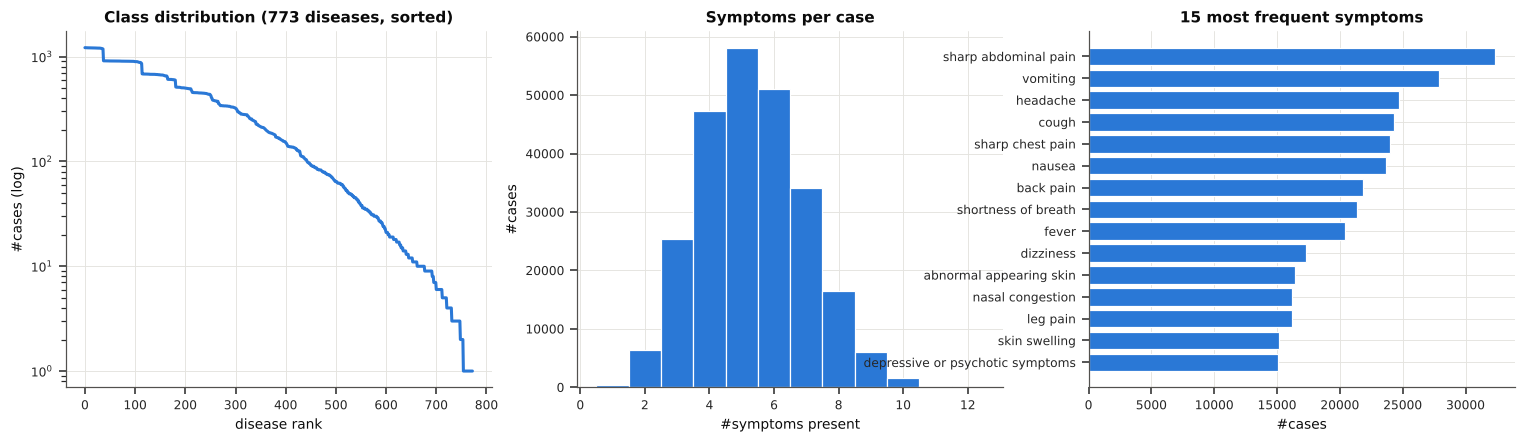

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
ax[0].plot(np.arange(len(vc_raw)), vc_raw.values, color="#2a78d6"); ax[0].set_yscale("log")
ax[0].set(title="Class distribution (773 diseases, sorted)", xlabel="disease rank", ylabel="#cases (log)")
k = Xraw.sum(1); ax[1].hist(k, bins=np.arange(0.5, k.max() + 1.5), color="#2a78d6", edgecolor="white")
ax[1].set(title="Symptoms per case", xlabel="#symptoms present", ylabel="#cases")
top = pd.Series(Xraw.sum(0), index=sym_names_all).sort_values(ascending=False).head(15)[::-1]
ax[2].barh(top.index, top.values, color="#2a78d6"); ax[2].set(title="15 most frequent symptoms", xlabel="#cases")
savefig("fig01_eda.png")

## 4. Data Preprocessing and Leakage-Free Experimental Protocol
1. Standardise labels (done above) and remove **exact duplicate records**.
2. Missing or malformed indicators would be set to 0 (absent). The audit shows there are none.
3. Drop **unused symptoms** (never present).
4. Keep diseases with at least `min_cases` unique cases so each disease can appear in train, validation and test.
5. **Leakage-free split**: a stratified *group* split where the *group is the symptom vector*. No symptom pattern in the
   test set is ever seen during training. The split stays stratified by disease.

In [7]:
df = raw.drop_duplicates().reset_index(drop=True)
X_all = df.drop(columns=LABEL).values
used = X_all.sum(0) > 0
vc = df[LABEL].value_counts()
keep_dis = vc[vc >= CFG["min_cases"]].index
df = df[df[LABEL].isin(keep_dis)].reset_index(drop=True)
X = df.drop(columns=LABEL).values[:, used].astype(np.float32)
sym_names = sym_names_all[used]
classes = np.array(sorted(df[LABEL].unique()))
cls2id = {c: i for i, c in enumerate(classes)}
y = df[LABEL].map(cls2id).values
groups = pd.util.hash_pandas_object(pd.DataFrame(X), index=False).values
S, C = X.shape[1], len(classes)
print(f"after preprocessing: {len(df):,} cases | {S} symptoms | {C} diseases "
      f"(dropped {audit['diseases'] - C} diseases with < {CFG['min_cases']} unique cases, "
      f"{audit['unused_symptoms']} unused symptoms)")

def grouped_split(y, groups, seed=42):
    """Stratified *group* split: every distinct symptom vector (group) goes to exactly one of train/val/test.
    Groups are stratified by their (majority) disease, so class proportions are preserved."""
    g = pd.DataFrame({"g": groups, "y": y})
    gl = g.groupby("g")["y"].agg(lambda s: s.value_counts().index[0])          # majority disease of each group
    gid, glab = gl.index.values, gl.values
    cnt = pd.Series(glab).map(pd.Series(glab).value_counts()).values
    strat = np.where(cnt >= 10, glab, -1)                                       # very rare strata pooled
    g_trv, g_te = train_test_split(gid, test_size=CFG["test_frac"], random_state=seed, stratify=strat)
    s2 = pd.Series(strat, index=gid)[g_trv].values
    g_tr, g_va = train_test_split(g_trv, test_size=CFG["val_frac"] / (1 - CFG["test_frac"]), random_state=seed, stratify=s2)
    where = pd.Series(0, index=gid); where[g_va] = 1; where[g_te] = 2
    w = where.reindex(groups).values
    return np.flatnonzero(w == 0), np.flatnonzero(w == 1), np.flatnonzero(w == 2)

t0 = time.time()
tr_idx, va_idx, te_idx = grouped_split(y, groups)
print(f"split in {time.time()-t0:.1f}s -> train {len(tr_idx):,} | val {len(va_idx):,} | test {len(te_idx):,}")
overlap = len(set(groups[te_idx]) & set(groups[tr_idx]))
print("symptom vectors shared by train and test:", overlap)
miss = set(range(C)) - set(y[tr_idx])
print("diseases absent from train:", len(miss), "| diseases present in test:", len(set(y[te_idx])))

after preprocessing: 189,409 cases | 328 symptoms | 658 diseases (dropped 115 diseases with < 5 unique cases, 49 unused symptoms)


split in 16.0s -> train 132,694 | val 18,947 | test 37,768
symptom vectors shared by train and test: 0
diseases absent from train: 0 | diseases present in test: 642


### 4.1 How much do common evaluation protocols leak?
We compare three protocols with the same simple MLP:
**(A)** random split on raw data (the usual practice), **(B)** random split after de-duplication, **(C)** our grouped split.
*Leak* is the fraction of test cases whose exact symptom vector also occurs in training.

,protocol,n_test,leaked_test_cases,MLP_top1,MLP_top5,test_top1_ceiling
0,"(A) random split, raw data",49239,0.4387,0.8602,0.9802,0.9681
1,"(B) random split, de-duplicated",37882,0.1509,0.8242,0.9731,0.9684
2,(C) grouped split (ours),37768,0.0000,0.8402,0.9770,0.8989


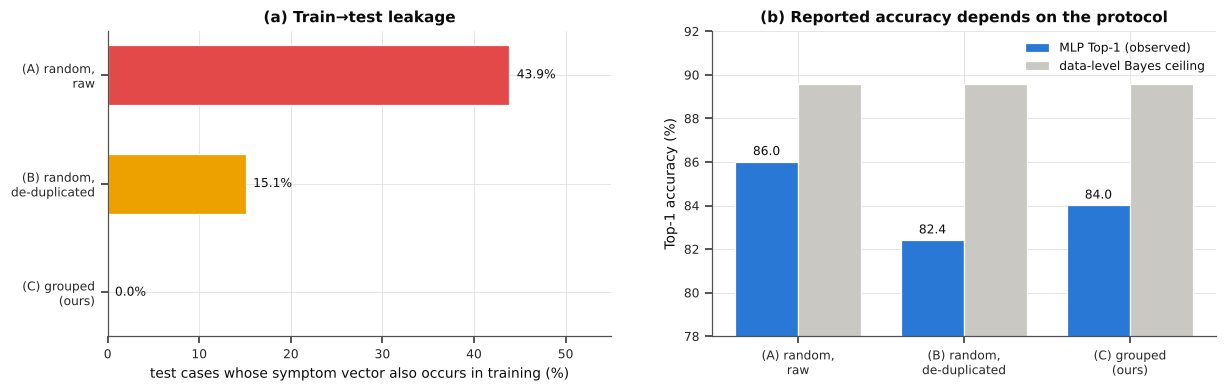

In [8]:
def mlp_quick(Xtr, ytr, Xte, yte, ncls, epochs=8, seed=0):
    set_seed(seed)
    m = nn.Sequential(nn.Linear(Xtr.shape[1], 512), nn.ReLU(), nn.Dropout(0.2), nn.Linear(512, ncls)).to(DEV)
    opt = torch.optim.AdamW(m.parameters(), 2e-3, weight_decay=1e-4)
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr)
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(yt))
        for i in range(0, len(yt), 512):
            b = perm[i:i + 512]; opt.zero_grad()
            F.cross_entropy(m(Xt[b].to(DEV)), yt[b].to(DEV)).backward(); opt.step()
    m.eval()
    with torch.no_grad():
        lo = torch.cat([m(torch.tensor(Xte[i:i + 4096]).to(DEV)).cpu() for i in range(0, len(Xte), 4096)])
    rank = (lo > lo.gather(1, torch.tensor(yte)[:, None])).sum(1) + 1
    return (rank == 1).float().mean().item(), (rank <= 5).float().mean().item()

leak_rows = []
# (A) raw, random split
ra = raw[raw[LABEL].isin(keep_dis)].reset_index(drop=True)
XA = ra.drop(columns=LABEL).values[:, used].astype(np.float32); yA = ra[LABEL].map(cls2id).values
gA = pd.util.hash_pandas_object(pd.DataFrame(XA), index=False).values
a_tr, a_te = train_test_split(np.arange(len(yA)), test_size=0.2, random_state=42, stratify=yA)
# (B) de-duplicated, random split
b_tr, b_te = train_test_split(np.arange(len(y)), test_size=0.2, random_state=42, stratify=y)
for name, (Xp, yp, gp, itr, ite) in {
        "(A) random split, raw data": (XA, yA, gA, a_tr, a_te),
        "(B) random split, de-duplicated": (X, y, groups, b_tr, b_te),
        "(C) grouped split (ours)": (X, y, groups, np.concatenate([tr_idx, va_idx]), te_idx)}.items():
    trset = set(gp[itr]); leak = np.mean([k in trset for k in gp[ite]])
    t1, t5 = mlp_quick(Xp[itr], yp[itr], Xp[ite], yp[ite], C)
    ce = bayes_ceiling(gp[ite], yp[ite], ks=(1,))["Top-1"]
    leak_rows.append(dict(protocol=name, n_test=len(ite), leaked_test_cases=round(leak, 4),
                          MLP_top1=round(t1, 4), MLP_top5=round(t5, 4), test_top1_ceiling=round(ce, 4)))
leak_df = pd.DataFrame(leak_rows); leak_df.to_csv(os.path.join(RES, "leakage_protocols.csv"), index=False)
show(leak_df)

fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
labs_p = ["(A) random,\nraw", "(B) random,\nde-duplicated", "(C) grouped\n(ours)"]
ax[0].barh(labs_p, leak_df.leaked_test_cases * 100, color=["#e34948", "#eda100", "#1baf7a"], height=0.55)
for j, v in enumerate(leak_df.leaked_test_cases * 100): ax[0].text(v + 0.8, j, f"{v:.1f}%", va="center", fontsize=8)
ax[0].invert_yaxis(); ax[0].set(xlabel="test cases whose symptom vector also occurs in training (%)", title="(a) Train→test leakage", xlim=(0, 55))
xx = np.arange(3); w = 0.38
ax[1].bar(xx - w / 2, leak_df.MLP_top1 * 100, w, color="#2a78d6", label="MLP Top-1 (observed)")
ax[1].bar(xx + w / 2, [ceil_dedup["Top-1"] * 100] * 3, w, color="#c9c8c2", label="data-level Bayes ceiling")
for j, v in enumerate(leak_df.MLP_top1 * 100): ax[1].text(j - w / 2, v + 0.3, f"{v:.1f}", ha="center", fontsize=8)
ax[1].set_xticks(xx); ax[1].set_xticklabels(labs_p); ax[1].set(ylim=(78, 92), ylabel="Top-1 accuracy (%)", title="(b) Reported accuracy depends on the protocol")
ax[1].legend(loc="upper right")
savefig("fig02_leakage_protocols.png")

### 4.2 Class-imbalance handling
Neural models use a **class-weighted** cross-entropy with $w_c \propto n_c^{-0.5}$ (normalised to mean 1) and mild label smoothing.
Training also uses **variable-rate symptom-masking augmentation**: each case draws its own rate $r\sim U(0, r_{max})$ and drops each present symptom with probability $r$, always keeping at least one.
This simulates patients who report only some of their symptoms and acts as resampling at the feature level.
We use re-weighting rather than oversampling because exact copies of rare cases would recreate the duplicate problem found in §2.

In [9]:
Xtr, ytr = X[tr_idx], y[tr_idx]; Xva, yva = X[va_idx], y[va_idx]; Xte, yte = X[te_idx], y[te_idx]
n_c = np.bincount(ytr, minlength=C).astype(np.float64)
cw = (np.maximum(n_c, 1) ** -CFG["cw_power"]); cw = cw / cw.mean()
class_w = torch.tensor(cw, dtype=torch.float32)
print("train class counts: min", int(n_c.min()), "median", int(np.median(n_c)), "max", int(n_c.max()))
print("class weight range: %.2f – %.2f" % (cw.min(), cw.max()))

train class counts: min 1 median 102 max 862
class weight range: 0.21 – 6.04


## 5. Methods I: Hypergraph Construction (Algorithm 1, training data only)
**Nodes**: the $|V|$ symptoms.

**Disease hyperedges** $E_d$: one per disease $d$, containing every symptom with $P(s\mid d) \ge \tau$. The incidence weight is $h_{sd}=P(s\mid d)$.

**Co-occurrence hyperedges** $E_c$: for every symptom $v$, the set $\{v\}\cup$ its top-$k$ partners by normalised PMI
(NPMI ≥ 0.10, co-count ≥ 10), de-duplicated. The weight is the mean NPMI. These capture symptom clusters that recur *across* diseases.

**Pairwise graph** (for the GCN/GAT baselines): the same NPMI statistics, but with only the top-10 pairwise edges per symptom.
This is the pairwise counterpart of $E_c$.

Node features $X^0$ combine a learnable identity embedding with a projection of the symptom's PPMI co-occurrence profile.

```text
Algorithm 1  HYPERGRAPH-CONSTRUCTION
──────────────────────────────────────────────────────────────────────────────
Input : training matrix X ∈ {0,1}^{N×|V|}, labels y ∈ {1..|D|}^N,
        membership threshold τ (=0.02), co-occurrence size k (=4),
        NPMI threshold η (=0.10), minimum co-count m (=10)
Output: incidence H ∈ {0,1}^{|V|×(|D|+|E_c|)}, soft weights W_H,
        pairwise graph A (baseline), node co-occurrence profile PPMI
──────────────────────────────────────────────────────────────────────────────
 1: n_d   ← Σ_i 1[y_i = d]                          ▷ cases per disease
 2: P(s|d)← Σ_i 1[y_i = d]·X_is / n_d               ▷ symptom prevalence
 3: for each disease d ∈ D do                         ▷ disease hyperedges E_d
 4:     e_d ← { s : P(s|d) ≥ τ };  w(s,e_d) ← P(s|d)
 5:     if e_d = ∅ then e_d ← top-3 symptoms of d by P(s|d)
 6: Co ← XᵀX ;  p_ij ← Co_ij / N ;  p_i ← Co_ii / N
 7: NPMI_ij ← log(p_ij / p_i p_j) / (−log p_ij);  PPMI_ij ← max(0, log(p_ij / p_i p_j))
 8: for each symptom v ∈ V do                         ▷ co-occurrence hyperedges E_c
 9:     N_v ← top-k { u : NPMI_vu ≥ η ∧ Co_vu ≥ m }
10:     if N_v ≠ ∅ then add hyperedge e = {v} ∪ N_v with weight mean_u NPMI_vu
11: remove duplicate hyperedges in E_c
12: A_vu ← 1 if u ∈ top-10 NPMI partners of v (symmetrised, + self-loops)
13: return H = [E_d ∥ E_c], W_H, A, PPMI
```

In [10]:
def build_structures(Xtr, ytr):
    Xs = sparse.csr_matrix(Xtr)
    # --- disease hyperedges
    Y = sparse.csr_matrix((np.ones(len(ytr)), (ytr, np.arange(len(ytr)))), shape=(C, len(ytr)))
    cnt = (Y @ Xs).toarray()                                # C x S counts
    p_sd = cnt / np.maximum(np.bincount(ytr, minlength=C)[:, None], 1)        # P(s|d)
    Hd = (p_sd >= CFG["dis_thresh"]) & (cnt >= 1)
    for d in np.where(Hd.sum(1) == 0)[0]:                   # safety: every disease gets a hyperedge
        Hd[d, np.argsort(-p_sd[d])[:3]] = True
    Wd = np.where(Hd, p_sd, 0.0)
    # --- co-occurrence statistics
    co = (Xs.T @ Xs).toarray().astype(np.float64); f = np.diag(co).copy(); N = len(ytr)
    pij = co / N; pi = f / N
    with np.errstate(divide="ignore", invalid="ignore"):
        pmi = np.log(pij / np.outer(pi, pi)); npmi = pmi / (-np.log(pij))
    npmi[~np.isfinite(npmi)] = -1; np.fill_diagonal(npmi, -1)
    ppmi = np.where(np.isfinite(pmi) & (pmi > 0), pmi, 0.0); np.fill_diagonal(ppmi, 0)
    ok = (npmi >= CFG["cooc_min_npmi"]) & (co >= CFG["cooc_min_count"])
    sets = {}
    for v in range(S):
        nb = [u for u in np.argsort(-npmi[v]) if ok[v, u]][:CFG["cooc_k"]]
        if nb:
            key = tuple(sorted([v] + nb))
            sets[key] = np.mean([npmi[v, u] for u in nb])
    Hc = np.zeros((len(sets), S), bool); Wc = np.zeros((len(sets), S))
    for i, (key, w) in enumerate(sets.items()):
        Hc[i, list(key)] = True; Wc[i, list(key)] = w
    # --- pairwise kNN graph (GCN / GAT)
    A = np.zeros((S, S), bool)
    for v in range(S):
        nb = [u for u in np.argsort(-npmi[v]) if ok[v, u]][:CFG["graph_k"]]
        A[v, nb] = True
    A = A | A.T; np.fill_diagonal(A, True)
    return dict(p_sd=p_sd, cnt=cnt, n_d=np.bincount(ytr, minlength=C), Hd=Hd, Wd=Wd, Hc=Hc, Wc=Wc, npmi=npmi, ppmi=ppmi, A=A, freq=f)

t0 = time.time(); ST = build_structures(Xtr, ytr)
print(f"built in {time.time()-t0:.1f}s")
hstats = pd.DataFrame({
    "hyperedge type": ["disease", "co-occurrence"],
    "count": [ST["Hd"].shape[0], ST["Hc"].shape[0]],
    "mean size": [ST["Hd"].sum(1).mean(), ST["Hc"].sum(1).mean()],
    "median size": [np.median(ST["Hd"].sum(1)), np.median(ST["Hc"].sum(1))],
    "max size": [ST["Hd"].sum(1).max(), ST["Hc"].sum(1).max()],
}).round(2)
node_deg = ST["Hd"].sum(0) + ST["Hc"].sum(0)
print("pairwise graph edges (undirected, excl. self):", int((ST["A"].sum() - S) / 2))
print("symptom node degree in hypergraph: mean %.1f, min %d, max %d" % (node_deg.mean(), node_deg.min(), node_deg.max()))
hstats.to_csv(os.path.join(RES, "hypergraph_stats.csv"), index=False); hstats

built in 0.3s
pairwise graph edges (undirected, excl. self): 1874
symptom node degree in hypergraph: mean 19.8, min 0, max 129


,hyperedge type,count,mean size,median size,max size
0,disease,658,7.72,8.0,12
1,co-occurrence,284,4.96,5.0,5


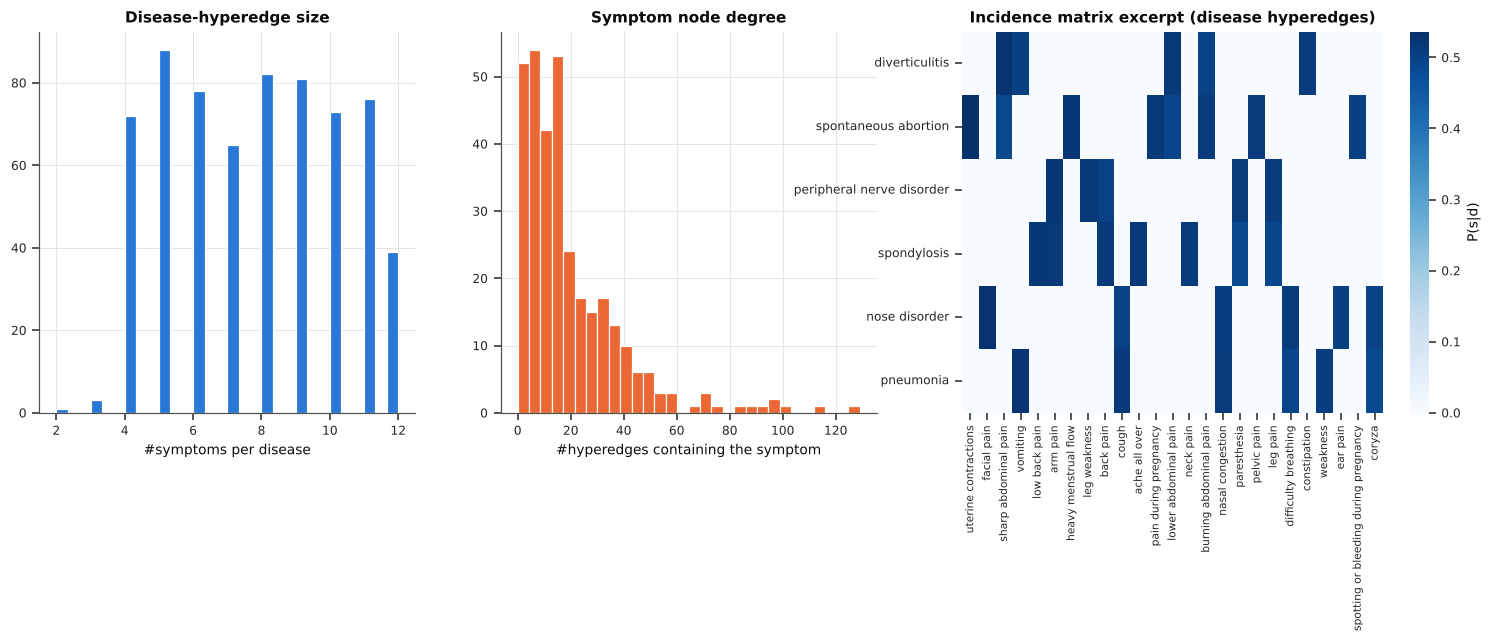

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5), gridspec_kw={"width_ratios": [1, 1, 1.4]})
ax[0].hist(ST["Hd"].sum(1), bins=30, color="#2a78d6", edgecolor="white"); ax[0].set(title="Disease-hyperedge size", xlabel="#symptoms per disease")
ax[1].hist(node_deg, bins=30, color="#eb6834", edgecolor="white"); ax[1].set(title="Symptom node degree", xlabel="#hyperedges containing the symptom")
ex = np.argsort(-n_c)[:12:2]
cols = np.where(ST["Hd"][ex].any(0))[0]
cols = cols[np.argsort(-ST["Wd"][ex][:, cols].max(0))][:25]
sns.heatmap(ST["Wd"][ex][:, cols], ax=ax[2], cmap="Blues", xticklabels=sym_names[cols], yticklabels=classes[ex], cbar_kws={"label": "P(s|d)"})
ax[2].set_title("Incidence matrix excerpt (disease hyperedges)"); ax[2].tick_params(axis="x", labelsize=7, rotation=90); ax[2].tick_params(axis="y", labelsize=8)
savefig("fig03_hypergraph_stats.png")

**Figure 4. A sub-hypergraph drawn as a star expansion.** Five related disease hyperedges (squares) and their member symptoms (circles).
Edge width ∝ $P(s\mid d)$. Symptoms shared by several diseases (dark) are exactly the cases where set-level reasoning is needed.

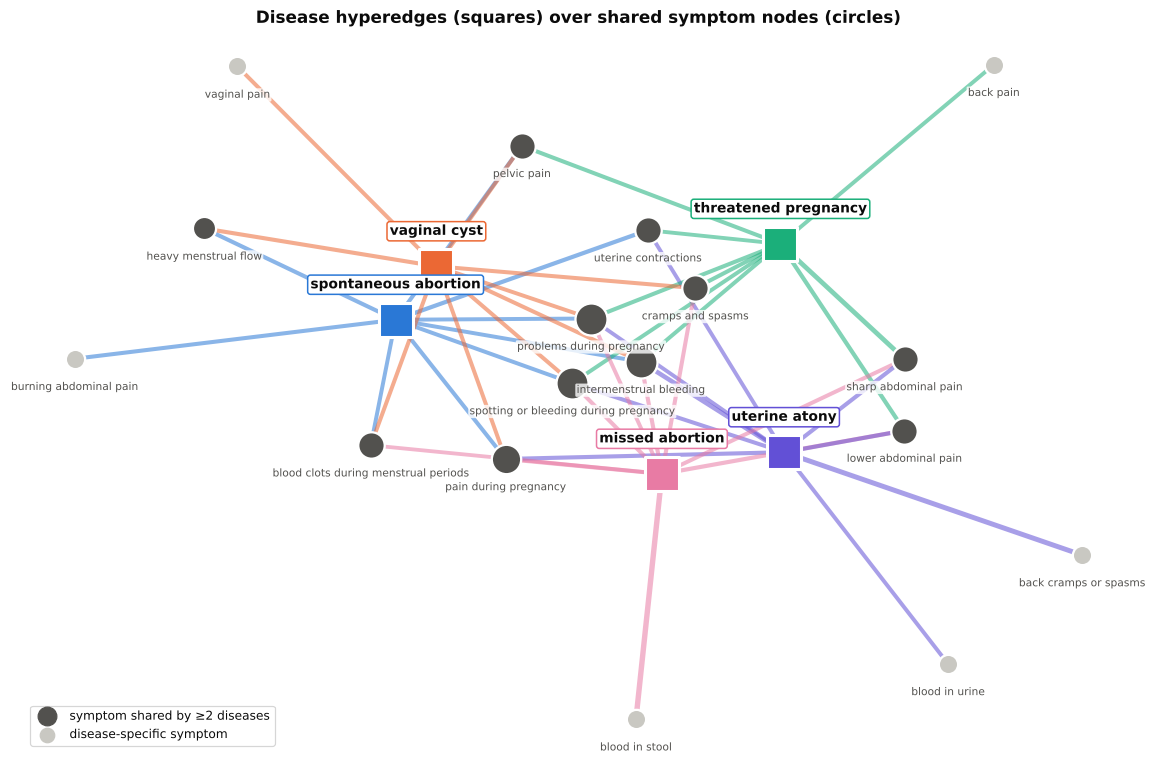

In [12]:
def jaccard_rows(Hb):
    Hb = Hb.astype(np.float32); inter = Hb @ Hb.T; sz = Hb.sum(1)
    return inter / np.maximum(sz[:, None] + sz[None] - inter, 1)
JAC = jaccard_rows(ST["Hd"])
d0 = int(np.argsort(-n_c)[2]); nbrs = [d0] + [int(i) for i in np.argsort(-JAC[d0]) if i != d0][:4]
G = nx.Graph(); dis_col = ["#2a78d6", "#eb6834", "#1baf7a", "#e87ba4", "#6250d6"]
for k_, d in enumerate(nbrs):
    G.add_node(f"D{d}", kind="d", label=classes[d], color=dis_col[k_])
    mem = np.flatnonzero(ST["Hd"][d]); mem = mem[np.argsort(-ST["p_sd"][d, mem])][:9]
    for v in mem:
        G.add_node(f"S{v}", kind="s", label=sym_names[v]); G.add_edge(f"D{d}", f"S{v}", w=ST["p_sd"][d, v], color=dis_col[k_])
pos = nx.spring_layout(G, seed=3, k=0.95, iterations=300)
fig, ax = plt.subplots(figsize=(13, 8.5)); ax.axis("off")
for u, v, a_ in G.edges(data=True):
    ax.plot(*zip(pos[u], pos[v]), color=a_["color"], lw=0.6 + 4 * a_["w"], alpha=0.55, zorder=1)
for nd, a_ in G.nodes(data=True):
    x_, y_ = pos[nd]
    if a_["kind"] == "d":
        ax.scatter(x_, y_, marker="s", s=520, color=a_["color"], edgecolor="white", lw=2, zorder=3)
        ax.text(x_, y_ + 0.075, a_["label"], ha="center", fontsize=9, fontweight="bold", color=INK, zorder=4,
                bbox=dict(boxstyle="round,pad=0.2", fc="white", ec=a_["color"], lw=1))
    else:
        deg = G.degree(nd)
        ax.scatter(x_, y_, s=90 + 70 * deg, color="#52514e" if deg > 1 else "#c9c8c2", edgecolor="white", lw=1.5, zorder=3)
        ax.text(x_, y_ - 0.055, a_["label"], ha="center", va="top", fontsize=7, color=INK2, zorder=4,
                bbox=dict(boxstyle="round,pad=0.12", fc="white", ec="none", alpha=0.8))
ax.set_title("Disease hyperedges (squares) over shared symptom nodes (circles)", fontsize=11)
ax.scatter([], [], s=150, color="#52514e", label="symptom shared by ≥2 diseases"); ax.scatter([], [], s=90, color="#c9c8c2", label="disease-specific symptom")
ax.legend(loc="lower left", fontsize=8, frameon=True)
savefig("fig04_hypergraph_network.png")

## 6. Methods II: Models
All neural models share the same training recipe (optimiser, class-weighted loss, augmentation, early stopping on validation MRR).
**Non-neural baselines:** Bernoulli Naive Bayes, Random Forest (size-capped so it fits in memory with 600+ classes), softmax Logistic Regression.
**Neural baselines:** MLP; GCN and GAT on the pairwise symptom graph; HGNN (Feng et al., 2019), a hypergraph convolution without attention.

**HyperDiag (proposed)**, with $L$ stacked dual-attention hypergraph layers:
* *Node-level attention* (node → hyperedge): $\alpha_{ve}=\mathrm{softmax}_{v\in e}\big(\mathrm{LReLU}(a^\top[W x_v \Vert U c_e]) + \log h_{ve}\big)$, $\;c_e \leftarrow \sum_v \alpha_{ve} W x_v$.
* *Hyperedge-level attention* (hyperedge → node): $\beta_{ev}=\mathrm{softmax}_{e\ni v}\big(\mathrm{LReLU}(b^\top[c_e \Vert W x_v])\big)$, $\;x_v \leftarrow \mathrm{LN}(x_v+\sigma(\sum_e \beta_{ev} c_e))$.
* *Patient query*: context-aware attention pooling over the patient's present symptoms ($\gamma_v$ is the symptom-evidence weight used for explanations).
* *Query-aware hyperedge attention*: the query attends over co-occurrence hyperedges that touch its symptoms and refines itself with the matched symptom clusters.
* *Disease-hyperedge prototype scoring*: $s_d = \langle \phi(q), \psi(c_d) \rangle/\tau + b_d$. Each disease is scored by its *own* hyperedge embedding, so structure is tied directly to the decision.
* *Hyperedge-likelihood evidence with query-adaptive gating*: each disease hyperedge has soft incidence $h_{vd}=P(v\mid d)$ (Laplace-smoothed).
  The final score adds generative evidence from the hyperedge,
  $s_d \mathrel{+}= \lambda_+(q)\sum_{v\in S}\log h_{vd} + \lambda_-(q)\sum_{v\notin S}\log(1-h_{vd})$,
  where $\lambda_\pm=\mathrm{softplus}(g([q;\log(1+|S|)]))$ are predicted *per patient*. When few symptoms are reported, the model can learn
  that missing symptoms carry little information, which pure discriminative models cannot express.

### 6.1 Formal description of HyperDiag

```text
Algorithm 2  HYPERDIAG-FORWARD  (scoring a query symptom set S)
──────────────────────────────────────────────────────────────────────────────
Input : query mask m ∈ {0,1}^{|V|} (S = {v : m_v = 1}); hypergraph (H, W_H);
        PPMI profile; L layers, h heads, width d
Output: disease scores s ∈ R^{|D|}; explanations γ (symptoms), α, β, π
──────────────────────────────────────────────────────────────────────────────
 1: X⁰ ← E_id + PPMI·W_p                              ▷ node initialisation
 2: C⁰_e ← Σ_v ŵ(v,e)·X⁰_v + t_type(e)                 ▷ hyperedge initialisation
 3: for ℓ = 1 … L do                                   ▷ dual-level message passing
 4:     Z ← X^{ℓ−1} W_v ;  Ĉ ← C^{ℓ−1} U_e
 5:     α_ve ← softmax_{v∈e}( LReLU(a_vᵀZ_v + a_eᵀĈ_e) + log w(v,e) )     ▷ node-level
 6:     M_e  ← Σ_{v∈e} α_ve Z_v ;  C^ℓ_e ← LN(C^{ℓ−1}_e + ELU(W_o M_e))
 7:     β_ev ← softmax_{e∋v}( LReLU(b_eᵀM_e + b_vᵀZ_v) )                  ▷ hyperedge-level
 8:     X^ℓ_v ← LN(X^{ℓ−1}_v + ELU(W_o' Σ_{e∋v} β_ev M_e))
 9: c̄ ← mean_{v∈S} X^L_v                               ▷ query context
10: γ_v ← softmax_{v∈S}( gᵀtanh(W X^L_v) + ⟨U c̄, X^L_v⟩/√d )             ▷ symptom evidence
11: q ← MLP([Σ_{v∈S} γ_v X^L_v ; c̄])
12: π_e ← softmax_{e∈E_c, e∩S≠∅}( ⟨W_q q, C^L_e⟩/√d );  q ← q + W_u Σ_e π_e C^L_e  ▷ query-aware
13: s_d ← exp(θ)·cos(q, ψ(C^L_d)) + b_d               ▷ disease-hyperedge prototype
14: (λ₊, λ₋) ← softplus(G[q ; log(1+|S|)])            ▷ query-adaptive gate
15: s_d ← s_d + λ₊ Σ_{v∈S} log h_vd + λ₋ Σ_{v∉S} log(1 − h_vd)          ▷ hyperedge evidence
16: return s, γ, α, β, π
```

**Complexity.** One layer costs $O(h\,\mathrm{nnz}(H)\,d)$. It is computed once per mini-batch, independent of batch size $B$.
The readout costs $O(B\,|V|\,d)$ and scoring $O(B\,|D|\,d)$.

### 6.1.1 Implementation

In [13]:
def masked_softmax(logits, mask, dim):
    logits = logits.masked_fill(~mask, -1e9)
    return torch.softmax(logits, dim) * mask

class SetAttnReadout(nn.Module):
    """Context-aware attention pooling over the symptoms present in a case."""
    def __init__(self, d):
        super().__init__(); self.W = nn.Linear(d, d); self.U = nn.Linear(d, d, bias=False); self.a = nn.Linear(d, 1, bias=False)
    def forward(self, Hn, M):                 # Hn: S x d, M: B x S (0/1)
        cnt = M.sum(1, keepdim=True).clamp(min=1)
        ctx = (M @ Hn) / cnt                  # B x d mean of present symptoms
        # score_v = a^T tanh(W h_v)  +  <U ctx, h_v>/sqrt(d): symptom salience + agreement with the rest of the case
        sc = self.a(torch.tanh(self.W(Hn))).squeeze(-1)[None] + (self.U(ctx) @ Hn.T) / math.sqrt(Hn.shape[1])
        g = masked_softmax(sc, M > 0, 1)
        return g @ Hn, ctx, g

class NodeInit(nn.Module):
    def __init__(self, d, ppmi):
        super().__init__()
        self.emb = nn.Parameter(torch.randn(S, d) * 0.1)
        P = torch.tensor(ppmi, dtype=torch.float32); self.register_buffer("P", P / (P.norm(dim=1, keepdim=True) + 1e-8))
        self.proj = nn.Linear(S, d, bias=False)
    def forward(self): return self.emb + self.proj(self.P)

class Head(nn.Module):
    def __init__(self, din, d, drop):
        super().__init__(); self.net = nn.Sequential(nn.Linear(din, d * 2), nn.GELU(), nn.Dropout(drop), nn.Linear(d * 2, C))
    def forward(self, z): return self.net(z)

class LogReg(nn.Module):
    def __init__(self, **k): super().__init__(); self.lin = nn.Linear(S, C)
    def forward(self, M): return self.lin(M)

class MLP(nn.Module):
    def __init__(self, d=128, drop=0.2, **k):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(S, 4 * d), nn.LayerNorm(4 * d), nn.GELU(), nn.Dropout(drop),
                                 nn.Linear(4 * d, 4 * d), nn.LayerNorm(4 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(4 * d, C))
    def forward(self, M): return self.net(M)

class GraphReadoutModel(nn.Module):
    """Shared shell for GCN / GAT / HGNN: node encoder -> attention readout -> MLP head."""
    def __init__(self, d, drop, ppmi):
        super().__init__(); self.init = NodeInit(d, ppmi); self.read = SetAttnReadout(d); self.head = Head(2 * d, d, drop); self.drop = nn.Dropout(drop)
    def encode(self): raise NotImplementedError
    def forward(self, M, return_att=False):
        Hn = self.encode(); z, ctx, g = self.read(Hn, M)
        out = self.head(torch.cat([z, ctx], 1))
        return (out, dict(gamma=g)) if return_att else out

class GCN(GraphReadoutModel):
    def __init__(self, d=128, layers=2, drop=0.2, ppmi=None, A=None, **k):
        super().__init__(d, drop, ppmi)
        A = torch.tensor(A, dtype=torch.float32); dinv = A.sum(1).rsqrt()
        self.register_buffer("Ah", dinv[:, None] * A * dinv[None])
        self.lins = nn.ModuleList([nn.Linear(d, d) for _ in range(layers)]); self.lns = nn.ModuleList([nn.LayerNorm(d) for _ in range(layers)])
    def encode(self):
        h = self.init()
        for lin, ln in zip(self.lins, self.lns): h = ln(h + self.drop(F.gelu(self.Ah @ lin(h))))
        return h

class GATLayer(nn.Module):
    def __init__(self, d, heads):
        super().__init__(); self.h, self.dh = heads, d // heads
        self.W = nn.Linear(d, d, bias=False); self.a_s = nn.Parameter(torch.randn(heads, self.dh) * 0.1); self.a_d = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
    def forward(self, x, mask):
        z = self.W(x).view(-1, self.h, self.dh)
        e = F.leaky_relu((z * self.a_d).sum(-1)[:, None] + (z * self.a_s).sum(-1)[None], 0.2)  # S x S x h
        att = masked_softmax(e, mask[:, :, None], 1)
        return torch.einsum("ijh,jhd->ihd", att, z).reshape(-1, self.h * self.dh)

class GAT(GraphReadoutModel):
    def __init__(self, d=128, layers=2, heads=4, drop=0.2, ppmi=None, A=None, **k):
        super().__init__(d, drop, ppmi); self.register_buffer("mask", torch.tensor(A))
        self.layers = nn.ModuleList([GATLayer(d, heads) for _ in range(layers)]); self.lns = nn.ModuleList([nn.LayerNorm(d) for _ in range(layers)])
    def encode(self):
        h = self.init()
        for lay, ln in zip(self.layers, self.lns): h = ln(h + self.drop(F.elu(lay(h, self.mask))))
        return h

def incidence(ST, use_cooc=True):
    Hm = ST["Hd"].T if not use_cooc else np.concatenate([ST["Hd"], ST["Hc"]]).T   # S x E
    Hw = ST["Wd"].T if not use_cooc else np.concatenate([ST["Wd"], ST["Wc"]]).T
    return torch.tensor(Hm), torch.tensor(Hw, dtype=torch.float32)

class HGNN(GraphReadoutModel):
    """Feng et al. (2019): X' = Dv^-1/2 H W De^-1 H^T Dv^-1/2 X Θ (no attention)."""
    def __init__(self, d=128, layers=2, drop=0.2, ppmi=None, ST=None, **k):
        super().__init__(d, drop, ppmi)
        Hm, Hw = incidence(ST); H = Hm.float()
        dv = H.sum(1).clamp(min=1); de = H.sum(0).clamp(min=1)
        self.register_buffer("G", (dv.rsqrt()[:, None] * H / de[None]) @ (H.T * dv.rsqrt()[None]))
        self.lins = nn.ModuleList([nn.Linear(d, d) for _ in range(layers)]); self.lns = nn.ModuleList([nn.LayerNorm(d) for _ in range(layers)])
    def encode(self):
        h = self.init()
        for lin, ln in zip(self.lins, self.lns): h = ln(h + self.drop(F.gelu(self.G @ lin(h))))
        return h

class DualAttnHyperLayer(nn.Module):
    def __init__(self, d, heads, drop, node_attn=True, edge_attn=True):
        super().__init__(); self.h, self.dh = heads, d // heads; self.node_attn, self.edge_attn = node_attn, edge_attn
        self.Wv = nn.Linear(d, d, bias=False); self.Ue = nn.Linear(d, d, bias=False)
        self.a_v = nn.Parameter(torch.randn(heads, self.dh) * 0.1); self.a_e = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
        self.b_e = nn.Parameter(torch.randn(heads, self.dh) * 0.1); self.b_v = nn.Parameter(torch.randn(heads, self.dh) * 0.1)
        self.out_e = nn.Linear(d, d); self.out_v = nn.Linear(d, d)
        self.ln_e = nn.LayerNorm(d); self.ln_v = nn.LayerNorm(d); self.drop = nn.Dropout(drop)
    def forward(self, x, c, Hm, logw, Hw_norm, Hdeg_norm):
        S_, E_ = Hm.shape
        z = self.Wv(x).view(S_, self.h, self.dh); ce = self.Ue(c).view(E_, self.h, self.dh)
        m3 = Hm[:, :, None]
        # node -> hyperedge (softmax over member nodes of each hyperedge)
        if self.node_attn:
            lg = F.leaky_relu((z * self.a_v).sum(-1)[:, None] + (ce * self.a_e).sum(-1)[None], 0.2) + logw[:, :, None]
            alpha = masked_softmax(lg, m3, 0)                       # S x E x h
        else:
            alpha = Hw_norm[:, :, None].expand(-1, -1, self.h)
        e_msg = torch.einsum("seh,shd->ehd", alpha, z)
        c_new = self.ln_e(c + self.drop(F.elu(self.out_e(e_msg.reshape(E_, -1)))))
        # hyperedge -> node (softmax over hyperedges incident to each node)
        if self.edge_attn:
            lg2 = F.leaky_relu((e_msg * self.b_e).sum(-1)[None] + (z * self.b_v).sum(-1)[:, None], 0.2)
            beta = masked_softmax(lg2, m3, 1)                       # S x E x h
        else:
            beta = Hdeg_norm[:, :, None].expand(-1, -1, self.h)
        v_msg = torch.einsum("seh,ehd->shd", beta, e_msg)
        x_new = self.ln_v(x + self.drop(F.elu(self.out_v(v_msg.reshape(S_, -1)))))
        return x_new, c_new, alpha, beta

class HyperDiag(nn.Module):
    def __init__(self, d=128, layers=2, heads=4, drop=0.2, ppmi=None, ST=None,
                 use_cooc=True, node_attn=True, edge_attn=True, proto=True, query_edge_attn=True, hyper_prior=True, **k):
        super().__init__()
        # hyperedge-likelihood evidence: smoothed soft incidence h_vd = P(v | disease-hyperedge d)
        h = (ST["cnt"] + 0.5) / (ST["n_d"][:, None] + 1.0)
        self.register_buffer("log_h", torch.tensor(np.log(h).T, dtype=torch.float32))        # S x C
        self.register_buffer("log_1mh", torch.tensor(np.log1p(-h).T, dtype=torch.float32))   # S x C
        self.hyper_prior = hyper_prior
        self.gate = nn.Linear(d + 1, 2)                       # query-adaptive weights of present / absent evidence
        nn.init.zeros_(self.gate.weight); nn.init.constant_(self.gate.bias, -3.0)   # start with weak evidence
        Hm, Hw = incidence(ST, use_cooc)
        self.register_buffer("Hm", Hm); self.register_buffer("logw", torch.log(Hw.clamp(min=1e-6)))
        self.register_buffer("Hw_norm", Hw / Hw.sum(0, keepdim=True).clamp(min=1e-9))
        Hf = Hm.float(); self.register_buffer("Hdeg_norm", Hf / Hf.sum(1, keepdim=True).clamp(min=1))
        self.nD = C; self.nE = Hm.shape[1]
        self.init = NodeInit(d, ppmi)
        self.etype = nn.Parameter(torch.randn(2, d) * 0.1)
        self.register_buffer("is_cooc", torch.arange(self.nE) >= C)
        self.layers = nn.ModuleList([DualAttnHyperLayer(d, heads, drop, node_attn, edge_attn) for _ in range(layers)])
        self.read = SetAttnReadout(d)
        self.use_cooc, self.qea, self.proto = use_cooc, query_edge_attn and use_cooc, proto
        self.q_att = nn.Linear(d, d, bias=False); self.q_upd = nn.Linear(d, d)
        self.qproj = nn.Sequential(nn.Linear(2 * d, 2 * d), nn.GELU(), nn.Dropout(drop), nn.Linear(2 * d, d))
        if proto:
            self.pproj = nn.Sequential(nn.Linear(d, d), nn.GELU(), nn.Linear(d, d))
            self.bias = nn.Parameter(torch.zeros(C)); self.logit_scale = nn.Parameter(torch.tensor(math.log(10.0)))
        else:
            self.head = Head(d, d, drop)
        self.drop = nn.Dropout(drop)

    def encode(self):
        x = self.init()
        c = (self.Hw_norm.T @ x) + self.etype[self.is_cooc.long()]
        atts = []
        for lay in self.layers:
            x, c, a, b = lay(x, c, self.Hm, self.logw, self.Hw_norm, self.Hdeg_norm); atts.append((a, b))
        return x, c, atts

    def forward(self, M, return_att=False):
        x, c, atts = self.encode()
        z, ctx, g = self.read(x, M)
        q = self.qproj(torch.cat([z, ctx], 1))
        q_alpha = None
        if self.qea:
            cc = c[C:]
            touch = (M @ self.Hm[:, C:].float()) > 0                  # co-occ. hyperedges touching the query
            sc = (self.q_att(q) @ cc.T) / math.sqrt(q.shape[1])
            q_alpha = masked_softmax(sc, touch, 1)
            q = q + self.drop(self.q_upd(q_alpha @ cc))
        if self.proto:
            P = self.pproj(c[:C])
            out = self.logit_scale.exp() * (F.normalize(q, dim=1) @ F.normalize(P, dim=1).T) + self.bias
        else:
            out = self.head(q)
        if self.hyper_prior:
            lam = F.softplus(self.gate(torch.cat([q, torch.log1p(M.sum(1, keepdim=True))], 1)))  # B x 2
            ev = lam[:, :1] * (M @ self.log_h) + lam[:, 1:] * ((1 - M) @ self.log_1mh)
            out = out + ev
        return (out, dict(gamma=g, layer_att=atts, q_alpha=q_alpha)) if return_att else out

print("models defined")

models defined


### 6.2 Training protocol and evaluation metrics (Algorithm 3)

```text
Algorithm 3  TRAINING AND EVALUATION PROTOCOL  (identical for every neural model)
──────────────────────────────────────────────────────────────────────────────
Input : grouped split (Tr, Va, Te); model f_θ; epochs T (=20); batch B (=1024);
        max masking rate r_max (=0.5); seeds {0,1,2}
──────────────────────────────────────────────────────────────────────────────
 1: w_c ← n_c^{−1/2} / mean_c(n_c^{−1/2})              ▷ class weights
 2: for seed ∈ seeds do
 3:     initialise θ;  AdamW(lr 2e−3, wd 1e−4) with a one-cycle schedule
 4:     for t = 1 … T do
 5:         for each mini-batch (M, y) ⊂ Tr do
 6:             r_i ~ U(0, r_max);  drop each present symptom of case i w.p. r_i   ▷ keep ≥ 1
 7:             ℒ ← CE_w(f_θ(M̃), y; label smoothing 0.05);  clip ‖∇‖ ≤ 5;  step
 8:         θ* ← θ if MRR(f_θ, Va) is the best so far       ▷ model selection
 9:     evaluate f_θ* on Te: ranks r_i = 1 + |{d : s_id > s_iy_i}|
10:     report Top-k, MRR, NDCG, ranks, P/R/F1, κ, MCC, log-loss, Brier, ECE, ...
11: aggregate mean ± std over seeds; run the statistical tests of §9
```

**Evaluation metrics** (all computed on the full ranking over $|D|=658$ diseases). Let $r_i$ be the rank of the true disease and $p_i$ the predicted distribution.

| Family | Metrics |
|---|---|
| Ranking (differential diagnosis) | Top-k accuracy $=\frac1N\sum_i 1[r_i\le k]$ (k = 1, 3, 5, 10); MRR $=\frac1N\sum_i 1/r_i$; NDCG@10 $=\frac1N\sum_i 1[r_i\le10]/\log_2(1+r_i)$; mean and median rank |
| Classification (top-1) | macro precision, macro recall (= balanced accuracy), macro-F1, weighted-F1, Cohen's κ, Matthews correlation coefficient (MCC) |
| Probabilistic / calibration | log-loss $=-\frac1N\sum_i\log p_{i,y_i}$; multi-class Brier score; expected calibration error (ECE, 15 bins); mean size of the 90%-probability differential set |
| Cost | trainable parameters, training time, inference time per 1,000 cases |

In [14]:
def augment(M, p):
    """Variable-rate symptom masking: each case gets its own drop rate ~ U(0, p)."""
    if p <= 0: return M
    rate = torch.rand(M.shape[0], 1, device=M.device) * p
    drop = (torch.rand_like(M) < rate) & (M > 0)
    Mn = M.masked_fill(drop, 0.0)
    empty = Mn.sum(1) == 0
    if empty.any(): Mn[empty] = M[empty]
    return Mn

@torch.no_grad()
def predict_logits(model, Xm, bs=4096):
    model.eval()
    return torch.cat([model(torch.as_tensor(Xm[i:i + bs]).to(DEV)).float().cpu() for i in range(0, len(Xm), bs)])

def rank_metrics(scores, yt, ks=(1, 3, 5, 10)):
    scores = torch.as_tensor(scores, dtype=torch.float32); yt_t = torch.as_tensor(yt)
    true = scores.gather(1, yt_t[:, None])
    rank = ((scores > true).sum(1) + 1).numpy()
    pred = scores.argmax(1).numpy()
    out = {f"Top-{k}": float((rank <= k).mean()) for k in ks}
    out["MRR"] = float((1.0 / rank).mean())
    labs = np.unique(yt)
    out["Macro-F1"] = float(f1_score(yt, pred, labels=labs, average="macro", zero_division=0))
    out["Weighted-F1"] = float(f1_score(yt, pred, labels=labs, average="weighted", zero_division=0))
    return out, rank, pred

def full_metrics(scores, yt, n_bins=15):
    """Comprehensive evaluation: ranking, classification, probabilistic and calibration metrics."""
    Sc = torch.as_tensor(np.asarray(scores), dtype=torch.float32); yt = np.asarray(yt); N = len(yt)
    P = torch.softmax(Sc, 1).numpy()
    rank = ((Sc > Sc.gather(1, torch.as_tensor(yt)[:, None])).sum(1) + 1).numpy()
    pred = P.argmax(1); conf = P.max(1); pt = P[np.arange(N), yt]; labs = np.unique(yt)
    o = {f"Top-{k}": (rank <= k).mean() for k in (1, 3, 5, 10)}
    o["MRR"] = (1.0 / rank).mean()
    o["NDCG@10"] = np.where(rank <= 10, 1.0 / np.log2(rank + 1), 0.0).mean()
    o["Mean rank"] = rank.mean(); o["Median rank"] = float(np.median(rank))
    pr, rc, f1, _ = precision_recall_fscore_support(yt, pred, labels=labs, average="macro", zero_division=0)
    o["Macro-P"], o["Macro-R"], o["Macro-F1"] = pr, rc, f1
    o["Weighted-F1"] = f1_score(yt, pred, labels=labs, average="weighted", zero_division=0)
    o["Cohen-kappa"] = cohen_kappa_score(yt, pred); o["MCC"] = matthews_corrcoef(yt, pred)
    o["Log-loss"] = float(-np.log(np.clip(pt, 1e-12, 1)).mean())
    o["Brier"] = float(((P ** 2).sum(1) - 2 * pt + 1).mean())
    corr = pred == yt; edges = np.linspace(0, 1, n_bins + 1); ece = 0.0
    for lo_, hi_ in zip(edges[:-1], edges[1:]):
        mk = (conf > lo_) & (conf <= hi_)
        if mk.any(): ece += mk.mean() * abs(corr[mk].mean() - conf[mk].mean())
    o["ECE"] = ece
    cs = np.cumsum(-np.sort(-P, 1), 1); o["Set size@90%"] = float(((cs < 0.9).sum(1) + 1).mean())
    return {k: float(v) for k, v in o.items()}, rank, P

def train_neural(builder, seed, Xtr, ytr, Xva, yva, verbose=True, tag=""):
    set_seed(seed); model = builder().to(DEV)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["lr"], weight_decay=CFG["weight_decay"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=CFG["lr"], total_steps=CFG["epochs"] * math.ceil(len(ytr) / CFG["batch"]), pct_start=0.1)
    Xt, yt = torch.tensor(Xtr), torch.tensor(ytr); w = class_w.to(DEV)
    best, best_state, bad, hist = -1, None, 0, []
    t0 = time.time()
    for ep in range(CFG["epochs"]):
        model.train(); perm = torch.randperm(len(yt)); tot = 0.0
        for i in range(0, len(yt), CFG["batch"]):
            b = perm[i:i + CFG["batch"]]
            M = augment(Xt[b].to(DEV), CFG["sym_dropout"])
            loss = F.cross_entropy(model(M), yt[b].to(DEV), weight=w, label_smoothing=CFG["label_smoothing"])
            opt.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(model.parameters(), 5.0); opt.step(); sched.step()
            tot += loss.item() * len(b)
        m, _, _ = rank_metrics(predict_logits(model, Xva), yva)
        hist.append(dict(epoch=ep + 1, loss=tot / len(yt), **{f"val_{k}": v for k, v in m.items()}))
        if m["MRR"] > best + 1e-5:
            best, bad = m["MRR"], 0; best_state = {k: v.detach().clone() for k, v in model.state_dict().items()}
        else:
            bad += 1
        if verbose and (ep % 5 == 0 or bad == 0 and ep == CFG["epochs"] - 1):
            print(f"  [{tag} s{seed}] ep{ep+1:02d} loss {tot/len(yt):.4f} val top1 {m['Top-1']:.4f} top5 {m['Top-5']:.4f} MRR {m['MRR']:.4f} ({time.time()-t0:.0f}s)")
        if bad >= CFG["patience"]: break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(hist), time.time() - t0

def partial_mask(Xm, r, seed=123):
    rs = np.random.RandomState(seed); out = np.zeros_like(Xm)
    for i, row in enumerate(Xm):
        on = np.flatnonzero(row); keep = max(1, int(math.ceil(r * len(on))))
        out[i, rs.choice(on, keep, replace=False)] = 1
    return out
PART = {r: (Xte if r == 1.0 else partial_mask(Xte, r)) for r in CFG["keep_ratios"]}   # shared partial-symptom test sets

def nparams(m): return sum(p.numel() for p in m.parameters() if p.requires_grad)

common = dict(d=CFG["dim"], layers=CFG["layers"], heads=CFG["heads"], drop=CFG["dropout"], ppmi=ST["ppmi"], A=ST["A"], ST=ST)
BUILDERS = {
    "LogReg (softmax)": lambda: LogReg(**common),
    "MLP": lambda: MLP(**common),
    "GCN (pairwise)": lambda: GCN(**common),
    "GAT (pairwise)": lambda: GAT(**common),
    "HGNN (hypergraph, no attention)": lambda: HGNN(**common),
    "HyperDiag (ours)": lambda: HyperDiag(**common),
}
for n, b in BUILDERS.items(): print(f"{n:34s} params = {nparams(b()):,}")

LogReg (softmax)                   params = 216,482
MLP                                params = 770,706
GCN (pairwise)                     params = 385,426
GAT (pairwise)                     params = 385,682
HGNN (hypergraph, no attention)    params = 385,426
HyperDiag (ours)                   params = 416,407


## 7. Experiments
### 7.1 Classical machine-learning baselines

In [15]:
results, store = [], {}   # store[(model, seed)] = test scores (logits / log-probabilities)
COST = {}                 # model -> dict(params, train_s, infer_ms_per_1k)
t0 = time.time()
nb = BernoulliNB(alpha=0.1).fit(sparse.csr_matrix(Xtr), ytr); t_nb = time.time() - t0
ti = time.time(); s_nb = nb.predict_log_proba(sparse.csr_matrix(Xte)); m, _, _ = rank_metrics(s_nb, yte)
COST["Naive Bayes (Bernoulli)"] = dict(params=int(nb.feature_log_prob_.size + nb.class_log_prior_.size), train_s=t_nb, infer_ms_per_1k=(time.time() - ti) / len(yte) * 1e6)
results.append(dict(model="Naive Bayes (Bernoulli)", seed=0, time_s=time.time() - t0, **m)); store[("Naive Bayes (Bernoulli)", 0)] = s_nb
print("NB", {k: round(v, 4) for k, v in m.items()}, f"{time.time()-t0:.0f}s")

t0 = time.time()
rf = RandomForestClassifier(n_estimators=60, max_leaf_nodes=4000, n_jobs=-1, random_state=0).fit(Xtr, ytr); t_rf = time.time() - t0
ti = time.time()
s_rf = np.concatenate([rf.predict_proba(Xte[i:i + 5000]) for i in range(0, len(Xte), 5000)])
s_rf = np.log(s_rf + 1e-6) + 1e-9 * np.random.RandomState(0).rand(*s_rf.shape)   # log-probabilities, tiny tie-break
m, _, _ = rank_metrics(s_rf, yte)
COST["Random Forest"] = dict(params=int(sum(t.tree_.node_count for t in rf.estimators_)), train_s=t_rf, infer_ms_per_1k=(time.time() - ti) / len(yte) * 1e6)
results.append(dict(model="Random Forest", seed=0, time_s=t_rf, **m)); store[("Random Forest", 0)] = s_rf
print("RF", {k: round(v, 4) for k, v in m.items()}, f"{time.time()-t0:.0f}s")
del rf

NB {'Top-1': 0.8431, 'Top-3': 0.9535, 'Top-5': 0.9767, 'Top-10': 0.9924, 'MRR': 0.9015, 'Macro-F1': 0.7643, 'Weighted-F1': 0.843} 2s


RF {'Top-1': 0.828, 'Top-3': 0.947, 'Top-5': 0.9736, 'Top-10': 0.9914, 'MRR': 0.8911, 'Macro-F1': 0.7102, 'Weighted-F1': 0.8232} 15s


### 7.2 Neural baselines and HyperDiag (three seeds each)

In [16]:
histories, trained, part_rows = {}, {}, []
for r, Xp in PART.items():
    m, _, _ = rank_metrics(nb.predict_log_proba(sparse.csr_matrix(Xp)), yte)
    part_rows.append(dict(model="Naive Bayes (Bernoulli)", keep_ratio=r, seed=0, **m))
for name, builder in BUILDERS.items():
    for seed in CFG["seeds"]:
        model, hist, tsec = train_neural(builder, seed, Xtr, ytr, Xva, yva, tag=name)
        ti = time.time(); lo = predict_logits(model, Xte); t_inf = time.time() - ti; m, _, _ = rank_metrics(lo, yte)
        if seed == CFG["seeds"][0]: COST[name] = dict(params=nparams(model), train_s=tsec, infer_ms_per_1k=t_inf / len(yte) * 1e6)
        results.append(dict(model=name, seed=seed, time_s=tsec, **m)); store[(name, seed)] = lo.numpy()
        for r, Xp in PART.items():
            mp, _, _ = rank_metrics(predict_logits(model, Xp), yte); part_rows.append(dict(model=name, keep_ratio=r, seed=seed, **mp))
        histories[(name, seed)] = hist
        if seed == CFG["seeds"][0]: trained[name] = model
        print(f"==> {name} seed {seed}: " + " ".join(f"{k} {v:.4f}" for k, v in m.items()) + f" | {tsec:.0f}s")
res_df = pd.DataFrame(results); res_df.to_csv(os.path.join(RES, "all_runs.csv"), index=False)

  [LogReg (softmax) s0] ep01 loss 7.0101 val top1 0.5361 top5 0.8422 MRR 0.6707 (1s)


  [LogReg (softmax) s0] ep06 loss 3.4411 val top1 0.8196 top5 0.9699 MRR 0.8849 (7s)


  [LogReg (softmax) s0] ep11 loss 2.9054 val top1 0.8366 top5 0.9729 MRR 0.8963 (12s)


  [LogReg (softmax) s0] ep16 loss 2.8018 val top1 0.8386 top5 0.9734 MRR 0.8980 (18s)


==> LogReg (softmax) seed 0: Top-1 0.8424 Top-3 0.9526 Top-5 0.9762 Top-10 0.9927 MRR 0.9008 Macro-F1 0.7516 Weighted-F1 0.8407 | 22s


  [LogReg (softmax) s1] ep01 loss 7.0111 val top1 0.5420 top5 0.8498 MRR 0.6736 (1s)


... (90 outputs left out)

  [HyperDiag (ours) s2] ep06 loss 2.3180 val top1 0.8401 top5 0.9755 MRR 0.8996 (77s)


  [HyperDiag (ours) s2] ep11 loss 2.2794 val top1 0.8414 top5 0.9753 MRR 0.9003 (139s)


  [HyperDiag (ours) s2] ep16 loss 2.2547 val top1 0.8435 top5 0.9758 MRR 0.9016 (199s)


==> HyperDiag (ours) seed 2: Top-1 0.8452 Top-3 0.9548 Top-5 0.9781 Top-10 0.9937 MRR 0.9033 Macro-F1 0.8131 Weighted-F1 0.8464 | 248s


## 8. Results
### 8.1 Table 2. Main comparison on the leakage-free test set (mean ± std over seeds, %)

In [17]:
METRICS = ["Top-1", "Top-3", "Top-5", "Top-10", "MRR", "Macro-F1", "Weighted-F1"]
order = ["Naive Bayes (Bernoulli)", "Random Forest"] + list(BUILDERS)
ours = "HyperDiag (ours)"
agg = res_df.groupby("model")[METRICS].agg(["mean", "std"]).reindex(order)
def fmt(a):
    out = pd.DataFrame(index=a.index)
    for mtr in METRICS:
        mu, sd = a[(mtr, "mean")] * 100, a[(mtr, "std")].fillna(0) * 100
        out[mtr] = [f"{x:.2f} ± {s:.2f}" for x, s in zip(mu, sd)]
    return out
table2 = fmt(agg)
ceil_test = bayes_ceiling(groups[te_idx], yte)
table2.loc["Bayes-optimal ceiling (test)"] = [f"{ceil_test.get(m, np.nan)*100:.2f}" if m in ceil_test else "—" for m in METRICS]
table2.to_csv(os.path.join(RES, "table2_comparison.csv"))
agg.to_csv(os.path.join(RES, "table2_comparison_raw.csv"))
table2

,Top-1,Top-3,Top-5,Top-10,MRR,Macro-F1,Weighted-F1
model,,,,,,,
Naive Bayes (Bernoulli),84.31 ± 0.00,95.35 ± 0.00,97.67 ± 0.00,99.24 ± 0.00,90.15 ± 0.00,76.43 ± 0.00,84.30 ± 0.00
Random Forest,82.80 ± 0.00,94.70 ± 0.00,97.36 ± 0.00,99.14 ± 0.00,89.11 ± 0.00,71.02 ± 0.00,82.32 ± 0.00
LogReg (softmax),84.24 ± 0.02,95.27 ± 0.02,97.62 ± 0.00,99.26 ± 0.02,90.08 ± 0.01,75.11 ± 0.21,84.07 ± 0.02
MLP,84.63 ± 0.03,95.49 ± 0.07,97.84 ± 0.01,99.38 ± 0.02,90.38 ± 0.01,81.71 ± 0.32,85.10 ± 0.04
GCN (pairwise),84.48 ± 0.01,95.49 ± 0.02,97.80 ± 0.00,99.35 ± 0.01,90.28 ± 0.01,81.12 ± 0.04,84.97 ± 0.04
GAT (pairwise),84.50 ± 0.03,95.48 ± 0.00,97.84 ± 0.04,99.36 ± 0.02,90.31 ± 0.02,81.35 ± 0.52,85.01 ± 0.02
"HGNN (hypergraph, no attention)",84.51 ± 0.04,95.48 ± 0.02,97.82 ± 0.02,99.36 ± 0.00,90.30 ± 0.02,81.28 ± 0.05,85.02 ± 0.05
HyperDiag (ours),84.57 ± 0.05,95.52 ± 0.04,97.82 ± 0.02,99.37 ± 0.03,90.36 ± 0.03,81.16 ± 0.13,84.72 ± 0.07
Bayes-optimal ceiling (test),89.89,98.37,99.55,99.96,—,—,—


### 8.2 Table 3. Comprehensive evaluation (20 metrics + cost; mean ± std over seeds)
Percentages for ranking, classification and ECE; raw values for ranks, log-loss, Brier score and set size.
↑ means higher is better and ↓ lower is better. The best value in each column is highlighted.

In [18]:
FM_rows, RANKS, CALIB = [], {}, {}
for (name, seed), sc in store.items():
    fm, rk, P_ = full_metrics(sc, yte)
    FM_rows.append(dict(model=name, seed=seed, **fm))
    if seed == 0:
        RANKS[name] = rk; CALIB[name] = (P_.max(1), P_.argmax(1) == yte)
    del P_
fm_df = pd.DataFrame(FM_rows); fm_df.to_csv(os.path.join(RES, "comprehensive_metrics_runs.csv"), index=False)
FULLM = ["Top-1", "Top-3", "Top-5", "Top-10", "MRR", "NDCG@10", "Mean rank", "Median rank", "Macro-P", "Macro-R",
         "Macro-F1", "Weighted-F1", "Cohen-kappa", "MCC", "Log-loss", "Brier", "ECE", "Set size@90%"]
PCT = {"Top-1", "Top-3", "Top-5", "Top-10", "MRR", "NDCG@10", "Macro-P", "Macro-R", "Macro-F1", "Weighted-F1", "Cohen-kappa", "MCC", "ECE"}
LOWER = {"Mean rank", "Median rank", "Log-loss", "Brier", "ECE", "Set size@90%", "Params", "Train time (s)", "Infer (ms/1k)"}
fm_mean = fm_df.groupby("model")[FULLM].mean().reindex(order); fm_std = fm_df.groupby("model")[FULLM].std().reindex(order).fillna(0)
cost_df = pd.DataFrame(COST).T.reindex(order).rename(columns={"params": "Params", "train_s": "Train time (s)", "infer_ms_per_1k": "Infer (ms/1k)"})
wide = pd.DataFrame(index=order)
for m_ in FULLM:
    sc_ = 100 if m_ in PCT else 1; dp = 2 if m_ in PCT else 3
    arrow = " ↓" if m_ in LOWER else " ↑"
    wide[m_ + arrow] = [f"{fm_mean.loc[i, m_]*sc_:.{dp}f} ± {fm_std.loc[i, m_]*sc_:.{dp}f}" if fm_std.loc[i, m_] > 0 else f"{fm_mean.loc[i, m_]*sc_:.{dp}f}" for i in order]
wide["Params ↓"] = [f"{int(v):,}" for v in cost_df["Params"]]
wide["Train time (s) ↓"] = cost_df["Train time (s)"].round(1).values
wide["Infer (ms/1k) ↓"] = cost_df["Infer (ms/1k)"].round(1).values
wide.index = [SHORT[i] for i in order]
wide.to_csv(os.path.join(RES, "table3_comprehensive_metrics.csv"))
num = pd.concat([fm_mean, cost_df], axis=1); num.index = wide.index; num.columns = list(wide.columns)
def _hl(col):
    v = num[col.name].astype(float); best = v.min() if col.name.endswith("↓") else v.max()
    return ["font-weight:bold; background-color:#dbe9f9" if np.isclose(x, best) else "" for x in v]
try:
    show(wide.style.apply(_hl, axis=0).set_caption("Table 3. Comprehensive evaluation on the leakage-free test set"))
except Exception:
    show(wide)

,Top-1 ↑,Top-3 ↑,Top-5 ↑,Top-10 ↑,MRR ↑,NDCG@10 ↑,Mean rank ↓,Median rank ↓,Macro-P ↑,Macro-R ↑,Macro-F1 ↑,Weighted-F1 ↑,Cohen-kappa ↑,MCC ↑,Log-loss ↓,Brier ↓,ECE ↓,Set size@90% ↓,Params ↓,Train time (s) ↓,Infer (ms/1k) ↓
NB,84.31,95.35,97.67,99.24,90.15,92.38,1.550,1.000,81.26,74.78,76.43,84.30,84.25,84.25,0.344,0.173,0.62,1.884,"216,482",1.300000,20.100000
RF,82.80,94.70,97.36,99.14,89.11,91.56,1.506,1.000,79.14,67.66,71.02,82.32,82.73,82.74,0.814,0.319,27.74,13.015,"479,940",12.600000,69.300000
LogReg,84.24 ± 0.02,95.27 ± 0.02,97.62 ± 0.00,99.26 ± 0.02,90.08 ± 0.01,92.32 ± 0.01,1.438 ± 0.000,1.000,79.89 ± 0.18,74.34 ± 0.19,75.11 ± 0.21,84.07 ± 0.02,84.18 ± 0.02,84.19 ± 0.02,0.643 ± 0.001,0.246 ± 0.000,16.40 ± 0.06,71.685 ± 0.346,"216,482",21.900000,1.700000
MLP,84.63 ± 0.03,95.49 ± 0.07,97.84 ± 0.01,99.38 ± 0.02,90.38 ± 0.01,92.58 ± 0.01,1.411 ± 0.003,1.000,82.69 ± 0.22,84.21 ± 0.46,81.71 ± 0.32,85.10 ± 0.04,84.58 ± 0.03,84.58 ± 0.03,0.451 ± 0.002,0.184 ± 0.000,9.26 ± 0.19,15.155 ± 0.920,"770,706",85.200000,4.800000
GCN,84.48 ± 0.01,95.49 ± 0.02,97.80 ± 0.00,99.35 ± 0.01,90.28 ± 0.01,92.50 ± 0.01,1.418 ± 0.001,1.000,83.19 ± 0.12,82.62 ± 0.11,81.12 ± 0.04,84.97 ± 0.04,84.42 ± 0.01,84.43 ± 0.01,0.534 ± 0.002,0.206 ± 0.001,14.86 ± 0.09,40.455 ± 0.661,"385,426",58.000000,4.000000
GAT,84.50 ± 0.03,95.48 ± 0.00,97.84 ± 0.04,99.36 ± 0.02,90.31 ± 0.02,92.52 ± 0.02,1.415 ± 0.001,1.000,83.27 ± 0.49,82.82 ± 0.56,81.35 ± 0.52,85.01 ± 0.02,84.44 ± 0.03,84.45 ± 0.03,0.532 ± 0.001,0.205 ± 0.000,14.76 ± 0.05,39.186 ± 0.287,"385,682",85.100000,6.600000
HGNN,84.51 ± 0.04,95.48 ± 0.02,97.82 ± 0.02,99.36 ± 0.00,90.30 ± 0.02,92.52 ± 0.01,1.416 ± 0.001,1.000,83.32 ± 0.10,82.90 ± 0.07,81.28 ± 0.05,85.02 ± 0.05,84.46 ± 0.04,84.46 ± 0.04,0.534 ± 0.000,0.205 ± 0.000,14.90 ± 0.06,40.504 ± 0.268,"385,426",59.900000,3.700000
HyperDiag,84.57 ± 0.05,95.52 ± 0.04,97.82 ± 0.02,99.37 ± 0.03,90.36 ± 0.03,92.57 ± 0.02,1.412 ± 0.002,1.000,83.02 ± 0.21,82.40 ± 0.15,81.16 ± 0.13,84.72 ± 0.07,84.52 ± 0.05,84.52 ± 0.05,0.538 ± 0.006,0.208 ± 0.002,16.28 ± 0.40,39.941 ± 3.160,"416,407",259.200000,15.500000


### 8.3 Table 4. Bootstrap 95% confidence intervals (seed 0, 1,000 resamples)
Case-level metrics (Top-k, MRR, NDCG) resample test cases. Macro-F1, the mean of per-disease F1, resamples **diseases**,
which gives an unbiased interval for the population of diseases.

In [19]:
B_IDX = np.random.RandomState(2024).randint(0, len(yte), (1000, len(yte)))
def boot_vec(v, idx=B_IDX):
    b = v[idx].mean(1); return v.mean(), np.percentile(b, 2.5), np.percentile(b, 97.5)
ci_rows = []
labs_te = np.unique(yte)
for name in order:
    rk = RANKS[name]; pred0 = np.asarray(store[(name, 0)]).argmax(1)
    row = {"model": SHORT[name]}
    for lab, v in [("Top-1", (rk <= 1).astype(float)), ("Top-5", (rk <= 5).astype(float)), ("MRR", 1.0 / rk),
                   ("NDCG@10", np.where(rk <= 10, 1 / np.log2(rk + 1), 0.0))]:
        mu_, lo_, hi_ = boot_vec(v); row[lab] = f"{mu_*100:.2f} [{lo_*100:.2f}, {hi_*100:.2f}]"
    f1d = f1_score(yte, pred0, labels=labs_te, average=None, zero_division=0)
    f1b = f1d[np.random.RandomState(7).randint(0, len(f1d), (1000, len(f1d)))].mean(1)
    row["Macro-F1"] = f"{f1d.mean()*100:.2f} [{np.percentile(f1b,2.5)*100:.2f}, {np.percentile(f1b,97.5)*100:.2f}]"
    ci_rows.append(row)
ci_df = pd.DataFrame(ci_rows).set_index("model"); ci_df.to_csv(os.path.join(RES, "table4_bootstrap_ci.csv")); ci_df

,Top-1,Top-5,MRR,NDCG@10,Macro-F1
model,,,,,
NB,"84.31 [83.94, 84.68]","97.67 [97.51, 97.83]","90.15 [89.91, 90.40]","92.38 [92.19, 92.58]","76.43 [74.40, 78.45]"
RF,"82.80 [82.45, 83.22]","97.36 [97.19, 97.52]","89.11 [88.88, 89.38]","91.56 [91.37, 91.77]","71.02 [68.76, 73.36]"
LogReg,"84.24 [83.89, 84.60]","97.62 [97.46, 97.77]","90.08 [89.84, 90.33]","92.32 [92.13, 92.52]","75.16 [73.05, 77.21]"
MLP,"84.66 [84.30, 85.01]","97.84 [97.69, 97.99]","90.37 [90.13, 90.60]","92.57 [92.38, 92.75]","81.55 [80.10, 83.01]"
GCN,"84.48 [84.13, 84.87]","97.81 [97.65, 97.95]","90.27 [90.04, 90.51]","92.49 [92.31, 92.69]","81.07 [79.52, 82.62]"
GAT,"84.52 [84.16, 84.87]","97.85 [97.70, 98.00]","90.32 [90.09, 90.56]","92.54 [92.36, 92.73]","81.82 [80.42, 83.28]"
HGNN,"84.48 [84.15, 84.86]","97.84 [97.69, 97.99]","90.29 [90.06, 90.53]","92.51 [92.33, 92.70]","81.34 [79.82, 82.81]"
HyperDiag,"84.60 [84.25, 84.97]","97.81 [97.65, 97.95]","90.38 [90.15, 90.62]","92.58 [92.40, 92.76]","81.09 [79.55, 82.60]"


### 8.4 Figure 6. Multi-view performance profile
**(a)** Radar of eight metrics (min–max normalised across models; larger is better).
**(b)** Cumulative match characteristic (CMC): Top-k accuracy for k = 1…20.
**(c)** Macro-F1 with bootstrap 95% CI. **(d)** Accuracy–efficiency trade-off (bubble area ∝ parameters).

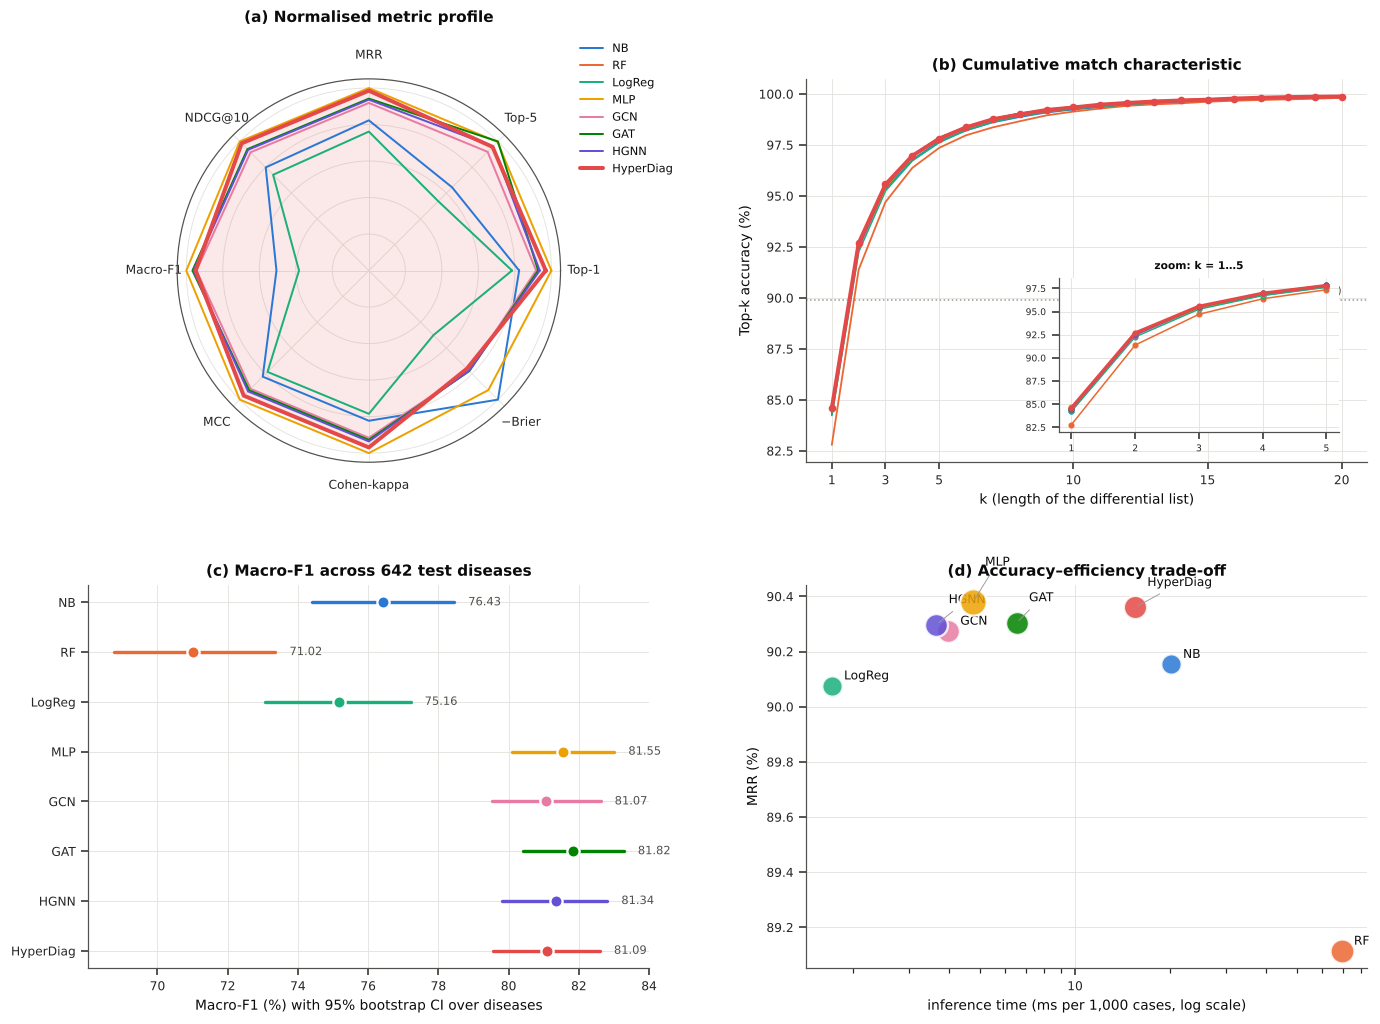

In [20]:
fig = plt.figure(figsize=(15, 10.5))
gs = fig.add_gridspec(2, 2, hspace=0.32, wspace=0.28)
axr = fig.add_subplot(gs[0, 0], polar=True)
RAD = ["Top-1", "Top-5", "MRR", "NDCG@10", "Macro-F1", "MCC", "Cohen-kappa", "Brier"]
vals = fm_mean[RAD].copy(); vals["Brier"] = -vals["Brier"]
norm = (vals - vals.min()) / (vals.max() - vals.min() + 1e-12)
ang = np.linspace(0, 2 * np.pi, len(RAD), endpoint=False).tolist(); ang += ang[:1]
for name in order:
    v = norm.loc[name].tolist(); v += v[:1]
    axr.plot(ang, v, color=COL[name], lw=2.6 if name == ours else 1.3, label=SHORT[name], zorder=5 if name == ours else 2)
    if name == ours: axr.fill(ang, v, color=COL[name], alpha=0.12)
axr.set_xticks(ang[:-1]); axr.set_xticklabels([r if r != "Brier" else "−Brier" for r in RAD], fontsize=8)
axr.set_yticklabels([]); axr.set_title("(a) Normalised metric profile", pad=18)
axr.legend(loc="upper right", bbox_to_anchor=(1.32, 1.12), fontsize=7.5)
ax = fig.add_subplot(gs[0, 1]); ks = np.arange(1, 21)
for name in order:
    ax.plot(ks, [(RANKS[name] <= k).mean() * 100 for k in ks], color=COL[name], lw=2.6 if name == ours else 1.2, marker="o" if name == ours else None, ms=4, label=SHORT[name])
ax.axhline(ceil_test["Top-1"] * 100, color=MUTED, ls=":", lw=1); ax.text(20, ceil_test["Top-1"] * 100 + 0.3, "Bayes ceiling (Top-1)", ha="right", fontsize=7, color=INK2)
ax.set(xlabel="k (length of the differential list)", ylabel="Top-k accuracy (%)", title="(b) Cumulative match characteristic", xticks=[1, 3, 5, 10, 15, 20])
axin = ax.inset_axes([0.45, 0.08, 0.5, 0.4])
for name in order: axin.plot(ks[:5], [(RANKS[name] <= k).mean() * 100 for k in ks[:5]], color=COL[name], lw=2.2 if name == ours else 1, marker="o", ms=3)
axin.set_title("zoom: k = 1…5", fontsize=7); axin.tick_params(labelsize=6); axin.set_xticks(range(1, 6))
ax = fig.add_subplot(gs[1, 0])
f1m = [float(ci_df.loc[SHORT[n], "Macro-F1"].split()[0]) for n in order]
f1lo = [float(ci_df.loc[SHORT[n], "Macro-F1"].split("[")[1].split(",")[0]) for n in order]
f1hi = [float(ci_df.loc[SHORT[n], "Macro-F1"].split(",")[1].strip(" ]")) for n in order]
yy = np.arange(len(order))
for j, n in enumerate(order):
    ax.plot([f1lo[j], f1hi[j]], [j, j], color=COL[n], lw=2.2); ax.plot(f1m[j], j, "o", color=COL[n], ms=8, mec="white", mew=1.5)
    ax.text(max(f1hi[j], f1m[j]) + 0.4, j, f"{f1m[j]:.2f}", va="center", fontsize=7.5, color=INK2)
ax.set_yticks(yy); ax.set_yticklabels([SHORT[n] for n in order]); ax.invert_yaxis()
ax.set(xlabel="Macro-F1 (%) with 95% bootstrap CI over diseases", title=f"(c) Macro-F1 across {len(labs_te)} test diseases")
ax = fig.add_subplot(gs[1, 1])
pts = sorted(order, key=lambda n: fm_mean.loc[n, "MRR"])
placed = []
for n in pts:
    x_, y_ = cost_df.loc[n, "Infer (ms/1k)"], fm_mean.loc[n, "MRR"] * 100
    ax.scatter(x_, y_, s=40 + 260 * np.sqrt(cost_df.loc[n, "Params"] / cost_df["Params"].max()), color=COL[n], alpha=0.85, edgecolor="white", lw=1.5, zorder=3)
    dy = 4
    for (px, py, pdy) in placed:          # simple label repulsion
        if abs(np.log10(px) - np.log10(x_)) < 0.25 and abs(py - y_) < 0.25: dy = pdy + 10
    placed.append((x_, y_, dy))
    ax.annotate(SHORT[n], (x_, y_), xytext=(8, dy), textcoords="offset points", fontsize=8, color=INK,
                arrowprops=dict(arrowstyle="-", color=MUTED, lw=0.6) if dy > 4 else None)
ax.set_xscale("log"); ax.xaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.xaxis.set_minor_formatter(matplotlib.ticker.NullFormatter()); ax.set(xlabel="inference time (ms per 1,000 cases, log scale)", ylabel="MRR (%)", title="(d) Accuracy–efficiency trade-off")
savefig("fig06_performance_profile.png")

### 8.5 Figure 7. Calibration: reliability diagrams
Bars show the empirical top-1 accuracy in each confidence bin. The diagonal is perfect calibration, and the shaded gap is miscalibration.

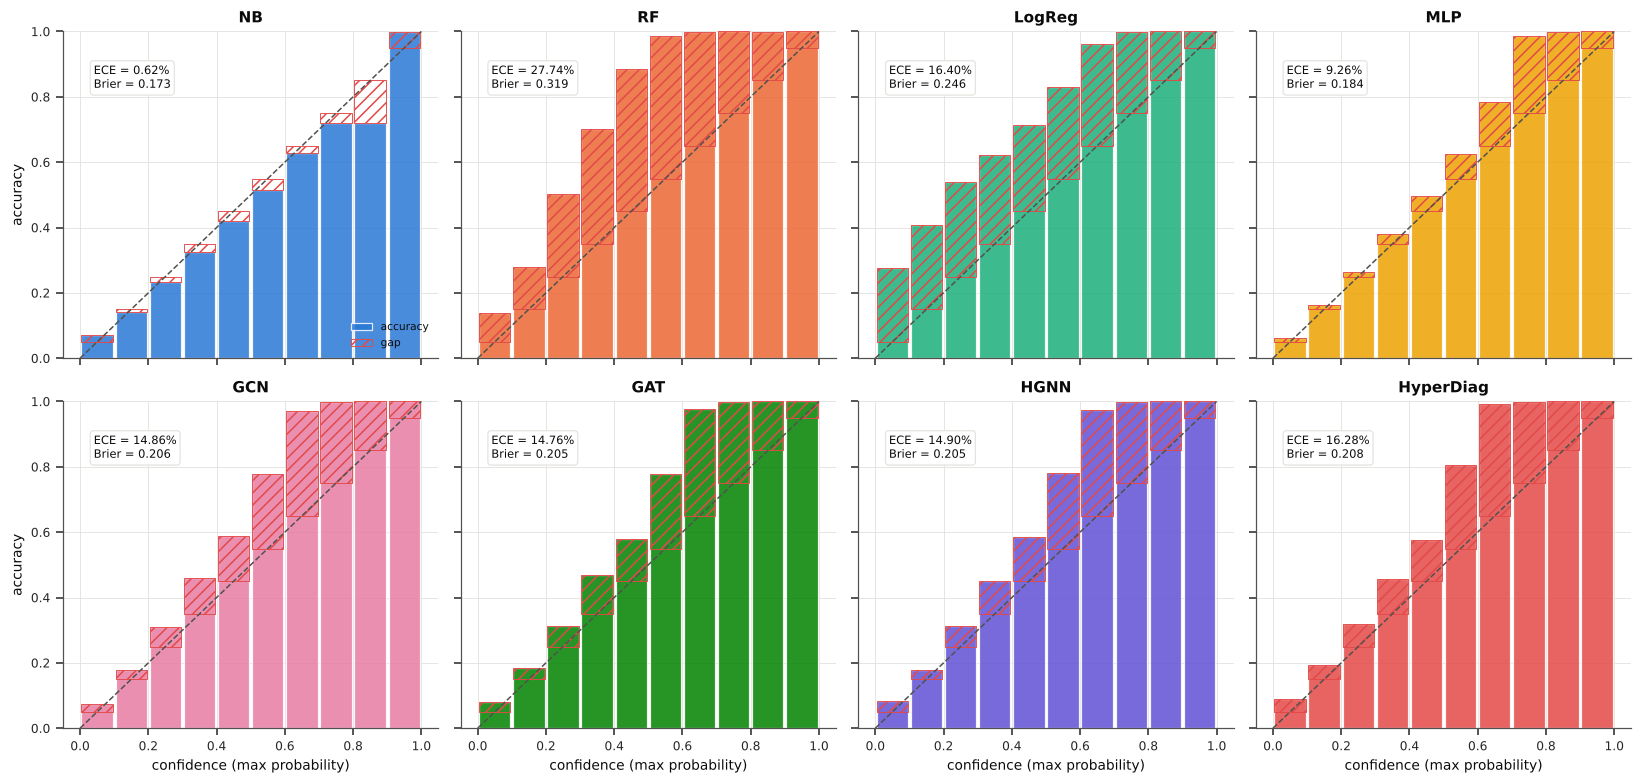

In [21]:
fig, axes = plt.subplots(2, 4, figsize=(15, 7.2), sharex=True, sharey=True)
edges = np.linspace(0, 1, 11)
for ax, n in zip(axes.ravel(), order):
    conf, corr = CALIB[n]; mids, accs, cnts = [], [], []
    for lo_, hi_ in zip(edges[:-1], edges[1:]):
        mk = (conf > lo_) & (conf <= hi_)
        mids.append((lo_ + hi_) / 2); accs.append(corr[mk].mean() if mk.any() else np.nan); cnts.append(mk.sum())
    mids, accs = np.array(mids), np.array(accs)
    ax.bar(mids, accs, width=0.092, color=COL[n], alpha=0.85, edgecolor="white", label="accuracy")
    ax.bar(mids, mids - np.nan_to_num(accs), bottom=np.nan_to_num(accs), width=0.092, color="none", edgecolor="#e34948", hatch="///", lw=0.6, label="gap")
    ax.plot([0, 1], [0, 1], color=INK2, ls="--", lw=1)
    ax.text(0.04, 0.9, f"ECE = {fm_mean.loc[n, 'ECE']*100:.2f}%\nBrier = {fm_mean.loc[n, 'Brier']:.3f}", fontsize=7.5, va="top",
            bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="#e4e3df"))
    ax.set_title(SHORT[n])
for ax in axes[1]: ax.set_xlabel("confidence (max probability)")
for ax in axes[:, 0]: ax.set_ylabel("accuracy")
axes[0, 0].legend(loc="lower right", fontsize=7)
plt.tight_layout(); savefig("fig07_calibration.png")

### 8.5.1 Table 5. Post-hoc temperature scaling (Guo et al., 2017)
Class weighting and label smoothing make the neural models **under-confident**: their bars lie above the diagonal.
A single temperature $T$ per model is fitted on the **validation** set by minimising NLL, then applied to the test logits.
Temperature scaling does not change rankings, so Top-k, MRR and F1 stay the same; only probability quality changes.

In [22]:
def fit_temperature(logits, y_):
    lg = torch.as_tensor(np.asarray(logits), dtype=torch.float32); yt_ = torch.as_tensor(y_)
    logT = torch.zeros(1, requires_grad=True); opt_ = torch.optim.LBFGS([logT], lr=0.1, max_iter=200)
    def closure():
        opt_.zero_grad(); l_ = F.cross_entropy(lg / logT.exp(), yt_); l_.backward(); return l_
    opt_.step(closure); return float(logT.exp())
ts_rows = []
val_scores = {"Naive Bayes (Bernoulli)": nb.predict_log_proba(sparse.csr_matrix(Xva))}
for n in BUILDERS: val_scores[n] = predict_logits(trained[n], Xva).numpy()
for n, vs_ in val_scores.items():
    T_ = fit_temperature(vs_, yva)
    before, _, _ = full_metrics(store[(n, 0)], yte); after, _, _ = full_metrics(np.asarray(store[(n, 0)]) / T_, yte)
    ts_rows.append({"model": SHORT[n], "T": round(T_, 3),
                    "ECE before (%)": before["ECE"] * 100, "ECE after (%)": after["ECE"] * 100,
                    "Log-loss before": before["Log-loss"], "Log-loss after": after["Log-loss"],
                    "Brier before": before["Brier"], "Brier after": after["Brier"],
                    "Set@90% before": before["Set size@90%"], "Set@90% after": after["Set size@90%"]})
ts_df = pd.DataFrame(ts_rows).set_index("model").round(3); ts_df.to_csv(os.path.join(RES, "table5_temperature_scaling.csv")); ts_df

,T,ECE before (%),ECE after (%),Log-loss before,Log-loss after,Brier before,Brier after,Set@90% before,Set@90% after
model,,,,,,,,,
NB,1.117,0.615,0.444,0.344,0.343,0.173,0.173,1.884,1.920
LogReg,0.435,16.382,2.363,0.643,0.362,0.246,0.181,71.521,2.422
MLP,0.621,9.165,2.322,0.450,0.337,0.183,0.173,14.715,1.817
GCN,0.542,14.960,2.381,0.536,0.345,0.206,0.176,41.219,1.816
GAT,0.536,14.815,2.269,0.533,0.343,0.205,0.175,39.511,1.819
HGNN,0.538,14.875,2.325,0.534,0.342,0.205,0.175,40.764,1.821
HyperDiag,0.489,15.917,1.569,0.532,0.332,0.206,0.171,37.109,1.825


### 8.6 Figure 8. Learning dynamics
Training loss and validation MRR per epoch (seed 0) for all neural models.

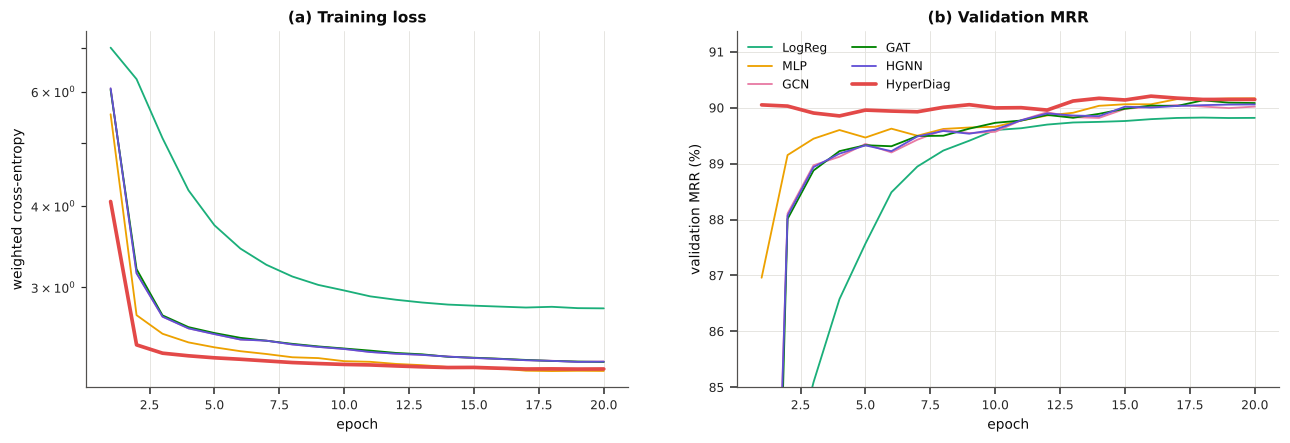

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for name in BUILDERS:
    h = histories[(name, CFG["seeds"][0])]
    ax[0].plot(h["epoch"], h["loss"], color=COL[name], lw=2.4 if name == ours else 1.2, label=SHORT[name])
    ax[1].plot(h["epoch"], h["val_MRR"] * 100, color=COL[name], lw=2.4 if name == ours else 1.2, label=SHORT[name])
ax[0].set(xlabel="epoch", ylabel="weighted cross-entropy", title="(a) Training loss"); ax[0].set_yscale("log")
ax[1].set(xlabel="epoch", ylabel="validation MRR (%)", title="(b) Validation MRR", ylim=(85, None)); ax[1].legend(ncol=2)
savefig("fig08_learning_dynamics.png")

## 9. Statistical Analysis
### 9.1 HyperDiag versus each baseline: McNemar's test and paired bootstrap
McNemar's test on top-1 correctness (with Holm–Bonferroni correction across the 7 comparisons) and paired bootstrap 95% CIs (1,000 resamples) of the Top-5/MRR differences (seed 0).

In [24]:
def mcnemar(c1, c2):
    b = int(((c1 == 1) & (c2 == 0)).sum()); c = int(((c1 == 0) & (c2 == 1)).sum())
    stat = (abs(b - c) - 1) ** 2 / max(b + c, 1); return b, c, 1 - chi2.cdf(stat, 1)

def boot_ci(a, b, n=1000, seed=0):
    rs = np.random.RandomState(seed); d = a - b; idx = rs.randint(0, len(d), (n, len(d)))
    bs = d[idx].mean(1); return d.mean(), np.percentile(bs, 2.5), np.percentile(bs, 97.5)

ours = "HyperDiag (ours)"
_, r_ours, _ = rank_metrics(store[(ours, CFG["seeds"][0])], yte)
sig = []
for name in order:
    if name == ours: continue
    _, r_b, _ = rank_metrics(store[(name, 0)], yte)
    b, c, p = mcnemar((r_ours == 1).astype(int), (r_b == 1).astype(int))
    d5, lo5, hi5 = boot_ci((r_ours <= 5).astype(float), (r_b <= 5).astype(float))
    dm, lom, him = boot_ci(1 / r_ours, 1 / r_b)
    sig.append(dict(baseline=name, ours_only_correct=b, baseline_only_correct=c, mcnemar_p=p,
                    dTop5=f"{d5*100:+.2f} [{lo5*100:+.2f}, {hi5*100:+.2f}]", dMRR=f"{dm*100:+.2f} [{lom*100:+.2f}, {him*100:+.2f}]"))
def holm(pvals):
    p_ = np.asarray(pvals, float); o_ = np.argsort(p_); m_ = len(p_); adj = np.empty(m_); run = 0.0
    for r_, i_ in enumerate(o_):
        run = max(run, min(1.0, (m_ - r_) * p_[i_])); adj[i_] = run
    return adj
def cohens_h(p1, p2): return 2 * np.arcsin(np.sqrt(p1)) - 2 * np.arcsin(np.sqrt(p2))
sig_df = pd.DataFrame(sig)
sig_df["mcnemar_p_holm"] = holm(sig_df["mcnemar_p"])
sig_df["cohens_h_top1"] = [cohens_h((r_ours == 1).mean(), (RANKS[n] == 1).mean()) for n in order if n != ours]
sig_df["significant (α=0.05, Holm)"] = np.where(sig_df["mcnemar_p_holm"] < 0.05, "yes", "no")
sig_df.to_csv(os.path.join(RES, "significance.csv"), index=False); sig_df

,baseline,ours_only_correct,baseline_only_correct,mcnemar_p,dTop5,dMRR,mcnemar_p_holm,cohens_h_top1,"significant (α=0.05, Holm)"
0,Naive Bayes (Bernoulli),1033,923,0.013718,"+0.14 [+0.01, +0.25]","+0.23 [+0.10, +0.36]",0.068588,0.008038,no
1,Random Forest,2292,1612,0.000000,"+0.45 [+0.30, +0.60]","+1.27 [+1.07, +1.45]",0.000000,0.048759,yes
2,LogReg (softmax),972,837,0.001630,"+0.19 [+0.08, +0.29]","+0.30 [+0.17, +0.43]",0.009778,0.009856,yes
3,MLP,978,1000,0.636799,"-0.03 [-0.14, +0.07]","+0.01 [-0.12, +0.15]",1.000000,-0.001615,no
4,GCN (pairwise),1105,1059,0.333369,"+0.00 [-0.11, +0.11]","+0.11 [-0.02, +0.25]",1.000000,0.003369,no
5,GAT (pairwise),1135,1107,0.568525,"-0.04 [-0.16, +0.07]","+0.06 [-0.09, +0.20]",1.000000,0.002052,no
6,"HGNN (hypergraph, no attention)",1101,1058,0.366046,"-0.03 [-0.15, +0.07]","+0.09 [-0.04, +0.23]",1.000000,0.003149,no


### 9.2 Figure 9. All-pairs McNemar test (Holm-corrected)
Cell (i, j) shows the signed $-\log_{10} p_{\text{Holm}}$: red means the row model is more often uniquely correct than the column model, blue the opposite.
Stars: * p<0.05, ** p<0.01, *** p<0.001.

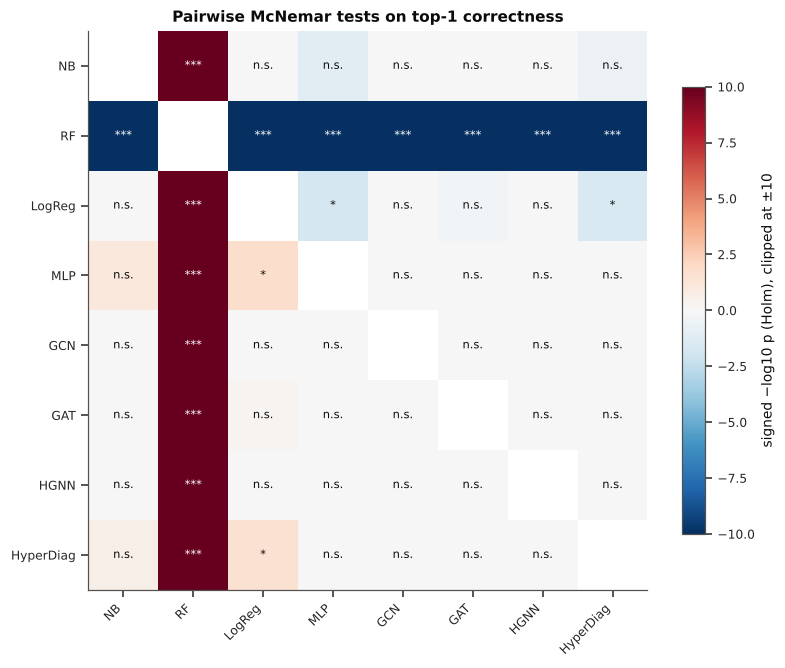

In [25]:
K = len(order); PM = np.zeros((K, K)); SG = np.zeros((K, K)); pairs, plist = [], []
for i in range(K):
    for j in range(i + 1, K):
        b, c, p = mcnemar((RANKS[order[i]] == 1).astype(int), (RANKS[order[j]] == 1).astype(int))
        pairs.append((i, j, np.sign(b - c))); plist.append(p)
padj = holm(plist)
for (i, j, sgn), pa in zip(pairs, padj):
    v = -np.log10(max(pa, 1e-300)); PM[i, j], PM[j, i] = sgn * v, -sgn * v; SG[i, j] = SG[j, i] = pa
fig, ax = plt.subplots(figsize=(8.2, 6.6))
lim = 10.0   # |−log10 p| ≥ 10 saturates the scale
np.fill_diagonal(PM, np.nan)
im = ax.imshow(np.clip(PM, -lim, lim), cmap=DIV, vmin=-lim, vmax=lim)
for i in range(K):
    for j in range(K):
        if i == j: continue
        st = "***" if SG[i, j] < 1e-3 else "**" if SG[i, j] < 1e-2 else "*" if SG[i, j] < 0.05 else "n.s."
        ax.text(j, i, st, ha="center", va="center", fontsize=7.5, color="white" if abs(PM[i, j]) > lim * 0.6 else INK)
ax.set_xticks(range(K)); ax.set_yticks(range(K)); ax.set_xticklabels([SHORT[o] for o in order], rotation=45, ha="right"); ax.set_yticklabels([SHORT[o] for o in order])
ax.grid(False); cb = plt.colorbar(im, ax=ax, shrink=0.8); cb.set_label("signed −log10 p (Holm), clipped at ±10")
ax.set_title("Pairwise McNemar tests on top-1 correctness")
savefig("fig09_pairwise_mcnemar.png")

### 9.3 Figure 10. Friedman test and Nemenyi critical-difference diagram
Models are ranked on each test disease by per-disease F1 (blocks = diseases). The Friedman test checks whether all models perform equally.
The Nemenyi post-hoc critical difference (CD, α = 0.05) connects models whose average ranks are **not** significantly different.

,test,statistic,df,p_value
0,Friedman χ²,383.95103,7,6.581039e-79
1,Iman–Davenport F,59.88070,"7, 4487",NaN
2,Nemenyi CD (α=0.05),0.41439,None,NaN


GAT          3.942
MLP          3.982
HGNN         4.093
GCN          4.164
HyperDiag    4.213
NB           4.783
LogReg       5.068
RF           5.755
Name: average rank (per-disease F1), dtype: float64

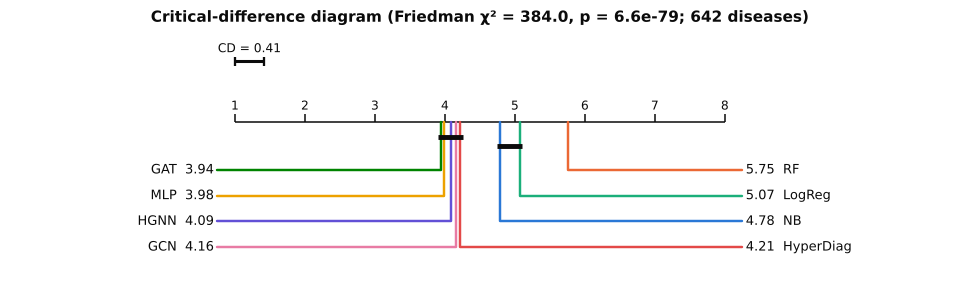

In [26]:
F1D = {n: f1_score(yte, np.asarray(store[(n, 0)]).argmax(1), labels=labs_te, average=None, zero_division=0) for n in order}
F1M = np.column_stack([F1D[n] for n in order])                 # diseases x models
ranks_bd = np.apply_along_axis(lambda r: rankdata(-r), 1, F1M)  # rank 1 = best
avg_rank = ranks_bd.mean(0)
fr_stat, fr_p = friedmanchisquare(*[F1M[:, k] for k in range(K)])
Nb = F1M.shape[0]; iman = (Nb - 1) * fr_stat / (Nb * (K - 1) - fr_stat)
Q05 = {2: 1.960, 3: 2.343, 4: 2.569, 5: 2.728, 6: 2.850, 7: 2.949, 8: 3.031, 9: 3.102, 10: 3.164}
CD = Q05[K] * np.sqrt(K * (K + 1) / (6 * Nb))
fried_df = pd.DataFrame([dict(test="Friedman χ²", statistic=fr_stat, df=K - 1, p_value=fr_p),
                         dict(test="Iman–Davenport F", statistic=iman, df=f"{K-1}, {(K-1)*(Nb-1)}", p_value=None),
                         dict(test="Nemenyi CD (α=0.05)", statistic=CD, df=None, p_value=None)])
fried_df.to_csv(os.path.join(RES, "friedman_nemenyi.csv"), index=False)
show(fried_df); show(pd.Series(avg_rank, index=[SHORT[o] for o in order], name="average rank (per-disease F1)").sort_values().round(3))

def cd_diagram(avg, names, cd, ax):
    k = len(names); lo, hi = 1, k; y0 = 0.78
    ax.set_xlim(lo - 3.2, hi + 3.2); ax.set_ylim(0.78 - 0.2 - 0.085 * ((k + 1) // 2), 1.08); ax.axis("off")
    ax.hlines(y0, lo, hi, color=INK, lw=1)
    for r in range(lo, hi + 1):
        ax.vlines(r, y0, y0 + 0.025, color=INK, lw=1); ax.text(r, y0 + 0.04, str(r), ha="center", fontsize=8)
    ax.hlines(0.98, lo, lo + cd, color=INK, lw=2); ax.vlines([lo, lo + cd], 0.965, 0.995, color=INK, lw=1.5)
    ax.text(lo + cd / 2, 1.0, f"CD = {cd:.2f}", ha="center", va="bottom", fontsize=8)
    oi = np.argsort(avg); half = (k + 1) // 2
    for j, i in enumerate(oi[:half]):
        r = avg[i]; yy = y0 - 0.16 - 0.085 * j
        ax.plot([r, r, lo - 0.25], [y0, yy, yy], color=COL[names[i]], lw=1.6)
        ax.text(lo - 0.3, yy, f"{SHORT[names[i]]}  {r:.2f}", ha="right", va="center", fontsize=8.5, color=INK)
    for j, i in enumerate(oi[half:][::-1]):
        r = avg[i]; yy = y0 - 0.16 - 0.085 * j
        ax.plot([r, r, hi + 0.25], [y0, yy, yy], color=COL[names[i]], lw=1.6)
        ax.text(hi + 0.3, yy, f"{r:.2f}  {SHORT[names[i]]}", ha="left", va="center", fontsize=8.5, color=INK)
    sr = np.sort(avg); cl = []
    for a_ in range(k):
        b_ = a_
        while b_ + 1 < k and sr[b_ + 1] - sr[a_] < cd: b_ += 1
        if b_ > a_ and not any(c0 <= a_ and b_ <= c1 for c0, c1 in cl): cl.append((a_, b_))
    for j, (a_, b_) in enumerate(cl):
        ax.hlines(y0 - 0.05 - 0.03 * j, sr[a_] - 0.04, sr[b_] + 0.04, color=INK, lw=3.2)

fig, ax = plt.subplots(figsize=(11, 3.0))
cd_diagram(avg_rank, order, CD, ax)
ax.set_title(f"Critical-difference diagram (Friedman χ² = {fr_stat:.1f}, p = {fmt_p(fr_p)}; {Nb} diseases)", fontsize=10)
savefig("fig10_critical_difference.png")

### 9.4 Table 6. Wilcoxon signed-rank tests on per-disease F1 (HyperDiag vs each baseline)
Paired over the test diseases, Holm-corrected. The effect size is the matched-pairs rank-biserial correlation $r_{rb}$
(|r| < 0.1 negligible, < 0.3 small, < 0.5 medium, otherwise large).

In [27]:
wil = []
for n in order:
    if n == ours: continue
    dlt = F1D[ours] - F1D[n]; nz = dlt[dlt != 0]
    st_, pw = wilcoxon(F1D[ours], F1D[n], zero_method="wilcox") if len(nz) else (np.nan, 1.0)
    rk_ = rankdata(np.abs(nz)); rrb = (rk_[nz > 0].sum() - rk_[nz < 0].sum()) / rk_.sum() if len(nz) else 0
    mag = "negligible" if abs(rrb) < 0.1 else "small" if abs(rrb) < 0.3 else "medium" if abs(rrb) < 0.5 else "large"
    wil.append(dict(baseline=SHORT[n], wins=int((dlt > 0).sum()), ties=int((dlt == 0).sum()), losses=int((dlt < 0).sum()),
                    median_dF1=np.median(dlt) * 100, mean_dF1=dlt.mean() * 100, W=st_, p=pw, r_rb=rrb, effect=mag))
wil_df = pd.DataFrame(wil); wil_df["p_holm"] = holm(wil_df["p"]); wil_df = wil_df.round(4)
wil_df.to_csv(os.path.join(RES, "table6_wilcoxon.csv"), index=False); wil_df

,baseline,wins,ties,losses,median_dF1,mean_dF1,W,p,r_rb,effect,p_holm
0,NB,276,153,213,0.0000,4.6588,45676.0,0.0000,0.2375,small,0.0000
1,RF,388,94,160,1.5957,10.0671,33350.5,0.0000,0.5566,large,0.0000
2,LogReg,342,128,172,0.2981,5.9308,38670.0,0.0000,0.4157,medium,0.0000
3,MLP,208,194,240,0.0000,-0.4644,46659.5,0.1857,-0.0722,negligible,0.5572
4,GCN,227,178,237,0.0000,0.0183,51990.0,0.4998,-0.0362,negligible,0.9429
5,GAT,209,177,256,0.0000,-0.7281,47899.0,0.0305,-0.1158,small,0.1219
6,HGNN,230,179,233,0.0000,-0.2468,51633.5,0.4714,-0.0386,negligible,0.9429


### 9.5 Figure 11. Paired bootstrap differences (HyperDiag − baseline) with 95% CI
Intervals that do not cross zero are statistically significant at the 5% level.

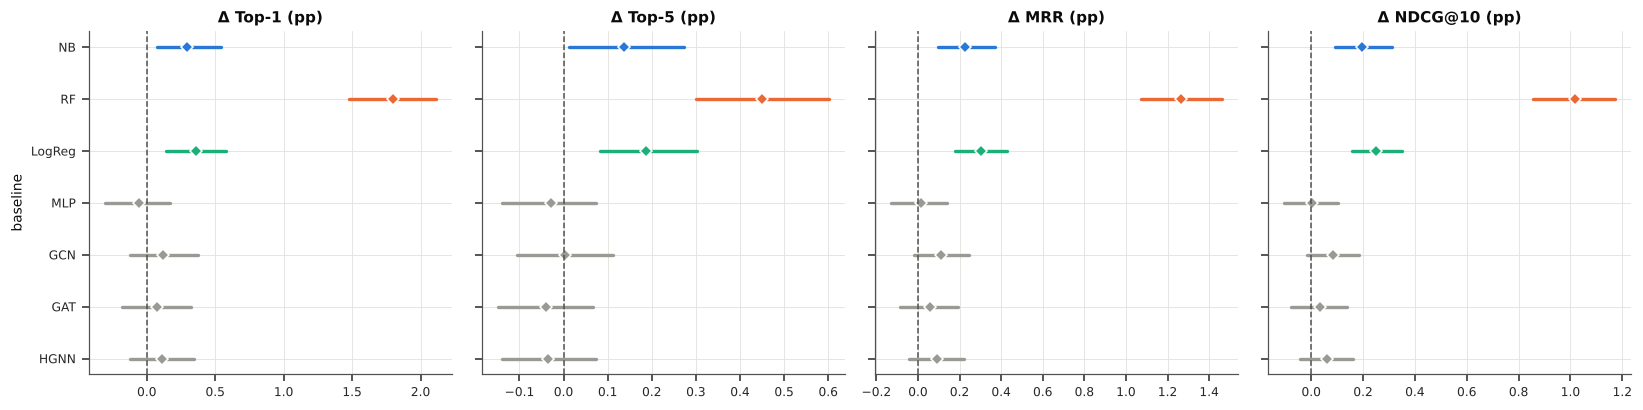

In [28]:
MET_V = {"Top-1": lambda r: (r <= 1).astype(float), "Top-5": lambda r: (r <= 5).astype(float),
         "MRR": lambda r: 1.0 / r, "NDCG@10": lambda r: np.where(r <= 10, 1 / np.log2(r + 1), 0.0)}
fig, axes = plt.subplots(1, 4, figsize=(15, 3.8), sharey=True)
fb = []
for ax, (mn, fn) in zip(axes, MET_V.items()):
    base_names = [n for n in order if n != ours]
    for j, n in enumerate(base_names):
        d_ = fn(RANKS[ours]) - fn(RANKS[n]); mu_, lo_, hi_ = boot_vec(d_)
        fb.append(dict(metric=mn, baseline=SHORT[n], delta=mu_ * 100, lo=lo_ * 100, hi=hi_ * 100))
        sigc = COL[n] if (lo_ > 0 or hi_ < 0) else MUTED
        ax.plot([lo_ * 100, hi_ * 100], [j, j], color=sigc, lw=2.2); ax.plot(mu_ * 100, j, "D", color=sigc, ms=6, mec="white")
    ax.axvline(0, color=INK2, lw=1, ls="--"); ax.set_title(f"Δ {mn} (pp)")
    ax.set_yticks(range(len(base_names))); ax.set_yticklabels([SHORT[n] for n in base_names])
axes[0].invert_yaxis(); axes[0].set_ylabel("baseline")
plt.tight_layout(); savefig("fig11_bootstrap_forest.png")
pd.DataFrame(fb).round(3).to_csv(os.path.join(RES, "bootstrap_differences.csv"), index=False)

## 10. Robustness to Partial Symptom Sets (RQ5)
Patients often report only part of their symptoms. Each test case keeps a random $\lceil r\cdot k\rceil$ of its $k$ symptoms (at least one).
The same masks are used for every model (computed during training in §7.2, mean over seeds shown).

In [29]:
part_df = pd.DataFrame(part_rows); part_df.to_csv(os.path.join(RES, "partial_symptoms.csv"), index=False)
piv = part_df.pivot_table(index="model", columns="keep_ratio", values="Top-5").reindex([o for o in order if o in part_df.model.unique()]) * 100
piv = piv[sorted(piv.columns, reverse=True)]; piv.columns = [f"keep {int(c*100)}%" for c in piv.columns]; piv.round(2)

,keep 100%,keep 80%,keep 60%,keep 40%,keep 20%
model,,,,,
Naive Bayes (Bernoulli),97.67,97.13,92.61,82.08,52.91
LogReg (softmax),97.62,97.02,92.17,80.62,50.23
MLP,97.84,97.28,91.97,79.11,44.59
GCN (pairwise),97.80,97.24,92.10,79.28,42.90
GAT (pairwise),97.84,97.28,92.09,79.29,42.82
"HGNN (hypergraph, no attention)",97.82,97.26,92.08,79.27,42.82
HyperDiag (ours),97.82,97.22,92.12,79.37,43.57


**Figure 12. Robustness to incomplete symptom reports.** (a, b) Heatmaps of Top-5 and MRR by fraction of symptoms kept;
(c) relative retention of Top-5 accuracy compared with the complete-symptom setting.

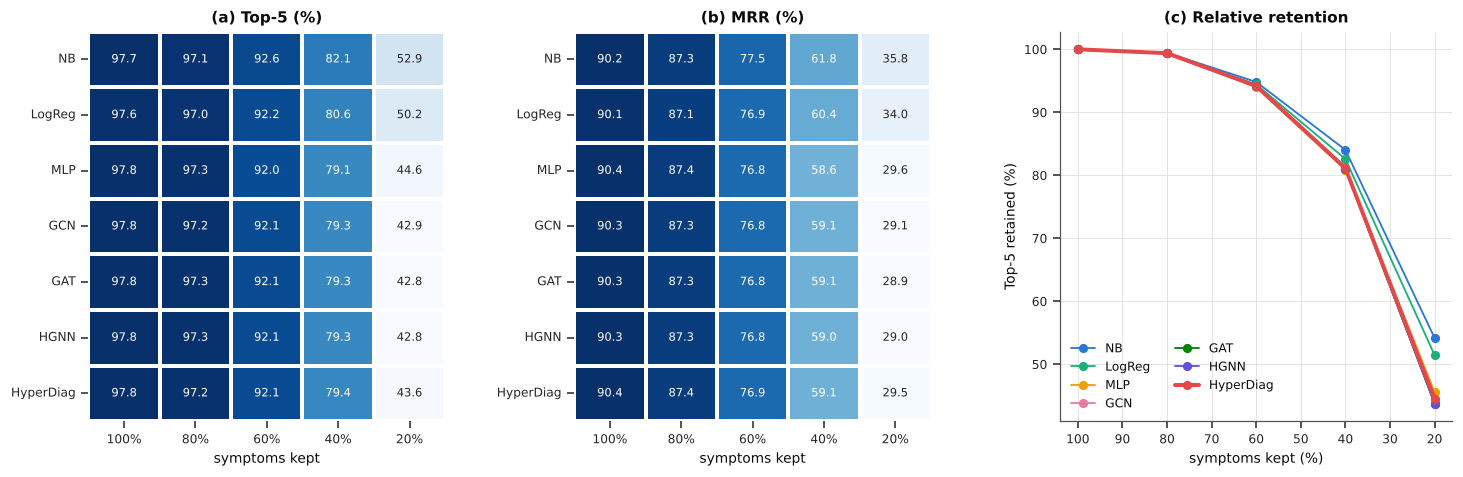

In [30]:
fig = plt.figure(figsize=(16, 4.6)); gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.1], wspace=0.35)
mods_p = [o for o in order if o in part_df.model.unique()]
for k_, mtr in enumerate(["Top-5", "MRR"]):
    ax = fig.add_subplot(gs[0, k_])
    hm = part_df.pivot_table(index="model", columns="keep_ratio", values=mtr).reindex(mods_p)[sorted(part_df.keep_ratio.unique(), reverse=True)] * 100
    sns.heatmap(hm, annot=True, fmt=".1f", cmap=SEQ, cbar=False, ax=ax, linewidths=1.5, linecolor="white", annot_kws={"fontsize": 7.5})
    ax.set_yticklabels([SHORT[m] for m in hm.index], rotation=0); ax.set_xticklabels([f"{int(c*100)}%" for c in hm.columns])
    ax.set(xlabel="symptoms kept", ylabel="", title=f"({'ab'[k_]}) {mtr} (%)")
ax = fig.add_subplot(gs[0, 2])
for m_ in mods_p:
    t5 = part_df[part_df.model == m_].groupby("keep_ratio")["Top-5"].mean()
    ax.plot(t5.index * 100, t5 / t5.loc[1.0] * 100, color=COL[m_], marker="o", lw=2.6 if m_ == ours else 1.2, label=SHORT[m_])
ax.invert_xaxis(); ax.set(xlabel="symptoms kept (%)", ylabel="Top-5 retained (%)", title="(c) Relative retention"); ax.legend(ncol=2)
savefig("fig12_partial_symptoms.png")

## 11. Rare versus Frequent Diseases (RQ6)
Diseases are grouped by number of training cases. We report per-group recall@1 and recall@5, averaged over the diseases in each group.

In [31]:
bins = [0, 20, 100, 400, 10**9]; labels_b = ["rare (≤20)", "low (21–100)", "mid (101–400)", "frequent (>400)"]
grp = pd.cut(n_c, bins=bins, labels=labels_b)
rare_rows = []
for name in order:
    rk = RANKS[name]
    t = pd.DataFrame({"y": yte, "r1": rk <= 1, "r5": rk <= 5})
    pc = t.groupby("y")[["r1", "r5"]].mean(); pc["grp"] = grp[pc.index]
    for gname, gg in pc.groupby("grp", observed=True):
        rare_rows.append(dict(model=name, group=gname, n_diseases=len(gg), recall1=gg.r1.mean(), recall5=gg.r5.mean()))
rare_df = pd.DataFrame(rare_rows); rare_df.to_csv(os.path.join(RES, "rare_diseases.csv"), index=False)
show((rare_df.pivot_table(index="model", columns="group", values="recall1", observed=True).reindex(order) * 100).round(2))

group,frequent (>400),low (21–100),mid (101–400),rare (≤20)
model,,,,
Naive Bayes (Bernoulli),83.36,75.36,86.96,51.29
Random Forest,84.81,68.11,80.77,36.83
LogReg (softmax),82.21,74.20,89.28,48.45
MLP,82.61,86.84,87.58,76.35
GCN (pairwise),82.90,83.96,86.82,74.84
GAT (pairwise),82.84,84.54,87.03,77.21
"HGNN (hypergraph, no attention)",82.77,84.47,86.98,75.79
HyperDiag (ours),82.63,84.73,87.82,73.24


**Figure 13. Per-disease F1 against training frequency.** Dots are individual diseases (HyperDiag). Lines are the mean F1 within
frequency quantile bins for each model, with the 95% CI of the mean shaded for HyperDiag.

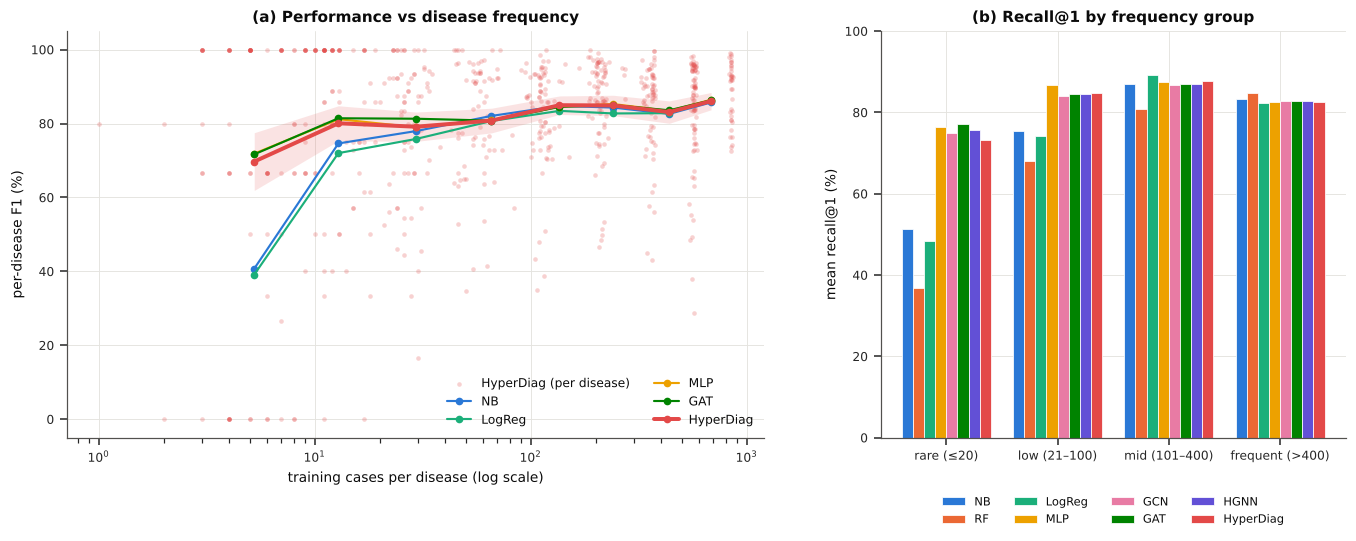

In [32]:
ntr = n_c[labs_te]
qb = np.unique(np.quantile(ntr, np.linspace(0, 1, 9)))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax[0].scatter(ntr, F1D[ours] * 100, s=9, color=COL[ours], alpha=0.25, lw=0, label="HyperDiag (per disease)")
for n in ["Naive Bayes (Bernoulli)", "LogReg (softmax)", "MLP", "GAT (pairwise)", ours]:
    xb, yb, lo_, hi_ = [], [], [], []
    for a_, b_ in zip(qb[:-1], qb[1:]):
        mk = (ntr >= a_) & (ntr <= b_)
        if mk.sum() < 3: continue
        v = F1D[n][mk] * 100; xb.append(np.exp(np.log(np.maximum(ntr[mk], 1)).mean())); yb.append(v.mean())
        se = v.std(ddof=1) / np.sqrt(len(v)); lo_.append(v.mean() - 1.96 * se); hi_.append(v.mean() + 1.96 * se)
    ax[0].plot(xb, yb, color=COL[n], lw=2.6 if n == ours else 1.4, marker="o", ms=4, label=SHORT[n])
    if n == ours: ax[0].fill_between(xb, lo_, hi_, color=COL[n], alpha=0.15, lw=0)
ax[0].set_xscale("log"); ax[0].set(xlabel="training cases per disease (log scale)", ylabel="per-disease F1 (%)", title="(a) Performance vs disease frequency")
ax[0].legend(ncol=2, loc="lower right")
g1 = rare_df.pivot_table(index="group", columns="model", values="recall1", observed=True).reindex(index=labels_b, columns=order) * 100
xx = np.arange(len(g1)); w = 0.8 / len(order)
for k_, n in enumerate(order):
    ax[1].bar(xx + (k_ - len(order) / 2 + 0.5) * w, g1[n], w, color=COL[n], label=SHORT[n], edgecolor="white", lw=0.5)
ax[1].set_xticks(xx); ax[1].set_xticklabels(g1.index, fontsize=8); ax[1].set(ylabel="mean recall@1 (%)", ylim=(0, 100), title="(b) Recall@1 by frequency group")
ax[1].legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.12), fontsize=7.5)
savefig("fig13_rare_diseases.png")

## 12. Ablation Study (Table 7)
Each component of HyperDiag is removed in turn and the model is retrained with the same seeds.

In [33]:
ABL = {
    "Full HyperDiag": {},
    "w/o co-occurrence hyperedges": dict(use_cooc=False),
    "w/o node-level attention": dict(node_attn=False),
    "w/o hyperedge-level attention": dict(edge_attn=False),
    "w/o both attentions": dict(node_attn=False, edge_attn=False),
    "w/o query-aware hyperedge attention": dict(query_edge_attn=False),
    "w/o prototype scoring (MLP head)": dict(proto=False),
    "w/o hyperedge-likelihood evidence": dict(hyper_prior=False),
}
abl_rows = []
for vname, kw in ABL.items():
    for seed in CFG["seeds"]:
        if vname == "Full HyperDiag":
            m, _, _ = rank_metrics(store[(ours, seed)], yte)
            mp = part_df[(part_df.model == ours) & (part_df.seed == seed) & (part_df.keep_ratio == 0.4)].iloc[0].to_dict()
        else:
            mdl, _, _ = train_neural(lambda: HyperDiag(**{**common, **kw}), seed, Xtr, ytr, Xva, yva, verbose=False, tag=vname)
            m, _, _ = rank_metrics(predict_logits(mdl, Xte), yte)
            mp, _, _ = rank_metrics(predict_logits(mdl, PART[0.4]), yte)
        abl_rows.append(dict(variant=vname, seed=seed, **m, **{"Top-5 @40% symptoms": mp["Top-5"]}))
        print(f"{vname:40s} s{seed} top1 {m['Top-1']:.4f} top5 {m['Top-5']:.4f} MRR {m['MRR']:.4f} F1 {m['Macro-F1']:.4f}")
abl_df = pd.DataFrame(abl_rows); abl_df.to_csv(os.path.join(RES, "ablation_runs.csv"), index=False)
AM = ["Top-1", "Top-5", "MRR", "Macro-F1", "Top-5 @40% symptoms"]
a = abl_df.groupby("variant")[AM].agg(["mean", "std"]).reindex(list(ABL))
table3 = pd.DataFrame({mtr: [f"{x*100:.2f} ± {(0 if np.isnan(s) else s)*100:.2f}" for x, s in zip(a[(mtr, "mean")], a[(mtr, "std")])] for mtr in AM}, index=a.index)
table3.to_csv(os.path.join(RES, "table7_ablation.csv")); a.to_csv(os.path.join(RES, "table7_ablation_raw.csv"))
show(table3)

Full HyperDiag                           s0 top1 0.8460 top5 0.9781 MRR 0.9038 F1 0.8109
Full HyperDiag                           s1 top1 0.8460 top5 0.9785 MRR 0.9037 F1 0.8109


Full HyperDiag                           s2 top1 0.8452 top5 0.9781 MRR 0.9033 F1 0.8131


w/o co-occurrence hyperedges             s0 top1 0.8473 top5 0.9781 MRR 0.9042 F1 0.8119


w/o co-occurrence hyperedges             s1 top1 0.8464 top5 0.9781 MRR 0.9038 F1 0.8108


w/o co-occurrence hyperedges             s2 top1 0.8456 top5 0.9782 MRR 0.9033 F1 0.8079


w/o node-level attention                 s0 top1 0.8453 top5 0.9780 MRR 0.9033 F1 0.8085


... (14 outputs left out)

w/o hyperedge-likelihood evidence        s0 top1 0.8450 top5 0.9786 MRR 0.9030 F1 0.8124


w/o hyperedge-likelihood evidence        s1 top1 0.8455 top5 0.9785 MRR 0.9031 F1 0.8115


w/o hyperedge-likelihood evidence        s2 top1 0.8445 top5 0.9778 MRR 0.9027 F1 0.8105


,Top-1,Top-5,MRR,Macro-F1,Top-5 @40% symptoms
variant,,,,,
Full HyperDiag,84.57 ± 0.05,97.82 ± 0.02,90.36 ± 0.03,81.16 ± 0.13,79.37 ± 0.11
w/o co-occurrence hyperedges,84.64 ± 0.08,97.81 ± 0.01,90.38 ± 0.05,81.02 ± 0.21,79.37 ± 0.13
w/o node-level attention,84.59 ± 0.09,97.82 ± 0.02,90.36 ± 0.06,81.12 ± 0.24,79.31 ± 0.03
w/o hyperedge-level attention,84.57 ± 0.03,97.81 ± 0.02,90.35 ± 0.01,81.11 ± 0.13,79.26 ± 0.04
w/o both attentions,84.61 ± 0.07,97.82 ± 0.03,90.36 ± 0.06,81.21 ± 0.14,79.32 ± 0.06
w/o query-aware hyperedge attention,84.66 ± 0.03,97.82 ± 0.05,90.39 ± 0.03,81.35 ± 0.11,79.26 ± 0.10
w/o prototype scoring (MLP head),84.40 ± 0.16,97.79 ± 0.07,90.23 ± 0.10,79.25 ± 1.07,79.98 ± 0.60
w/o hyperedge-likelihood evidence,84.50 ± 0.05,97.83 ± 0.04,90.29 ± 0.02,81.15 ± 0.10,79.36 ± 0.16


**Figure 14. Ablation effects.** Change relative to the full model (mean over seeds, in percentage points). Error bars: ±1 std of the
seed-paired difference. Red bars mark a drop larger than one standard deviation.

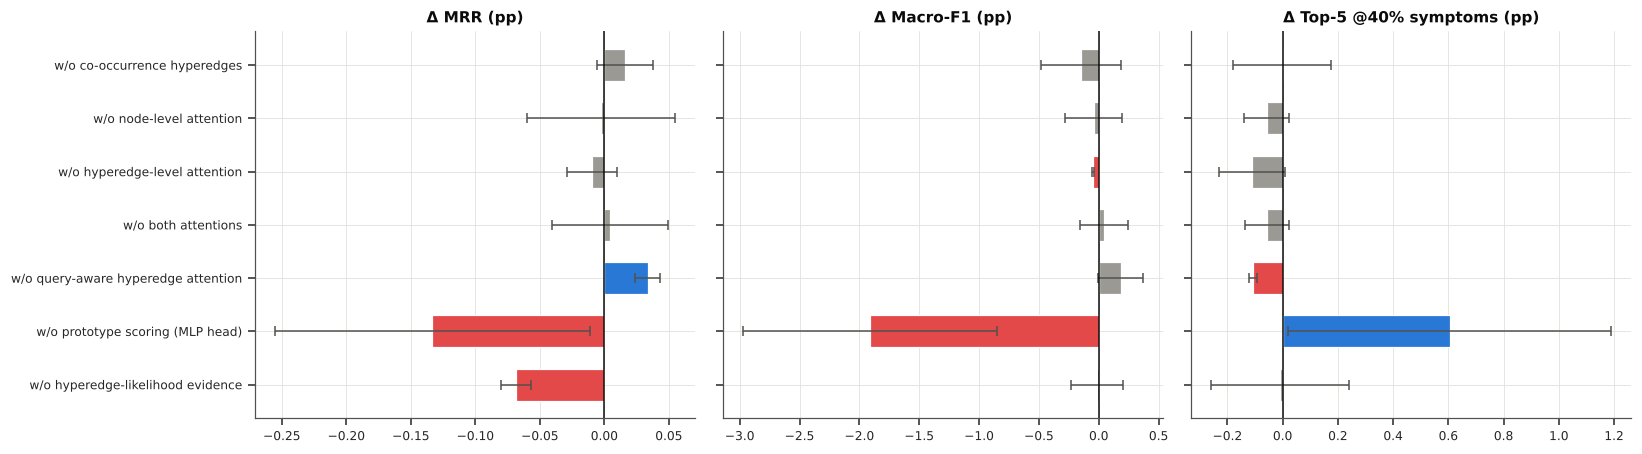

In [34]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
vs = [v for v in ABL if v != "Full HyperDiag"]
for ax, mtr in zip(axes, ["MRR", "Macro-F1", "Top-5 @40% symptoms"]):
    full_ = abl_df[abl_df.variant == "Full HyperDiag"].set_index("seed")[mtr]
    mu_, sd_ = [], []
    for v in vs:
        d_ = (abl_df[abl_df.variant == v].set_index("seed")[mtr] - full_) * 100; mu_.append(d_.mean()); sd_.append(d_.std() if len(d_) > 1 else 0)
    cols = ["#e34948" if m_ < -s_ and m_ < 0 else "#2a78d6" if m_ > s_ else MUTED for m_, s_ in zip(mu_, sd_)]
    ax.barh(range(len(vs)), mu_, xerr=sd_, color=cols, height=0.6, error_kw=dict(ecolor=INK2, lw=1, capsize=3))
    ax.axvline(0, color=INK, lw=1); ax.set_title(f"Δ {mtr} (pp)")
axes[0].set_yticks(range(len(vs))); axes[0].set_yticklabels(vs); axes[0].invert_yaxis()
plt.tight_layout(); savefig("fig14_ablation.png")

## 13. Interpretability and Explanation Faithfulness (RQ4, RQ7)
### 13.1 Case studies: differential diagnosis with symptom-evidence attention
For a test patient, HyperDiag returns a ranked top-5 differential and the weight $\gamma_v$ of every reported symptom.

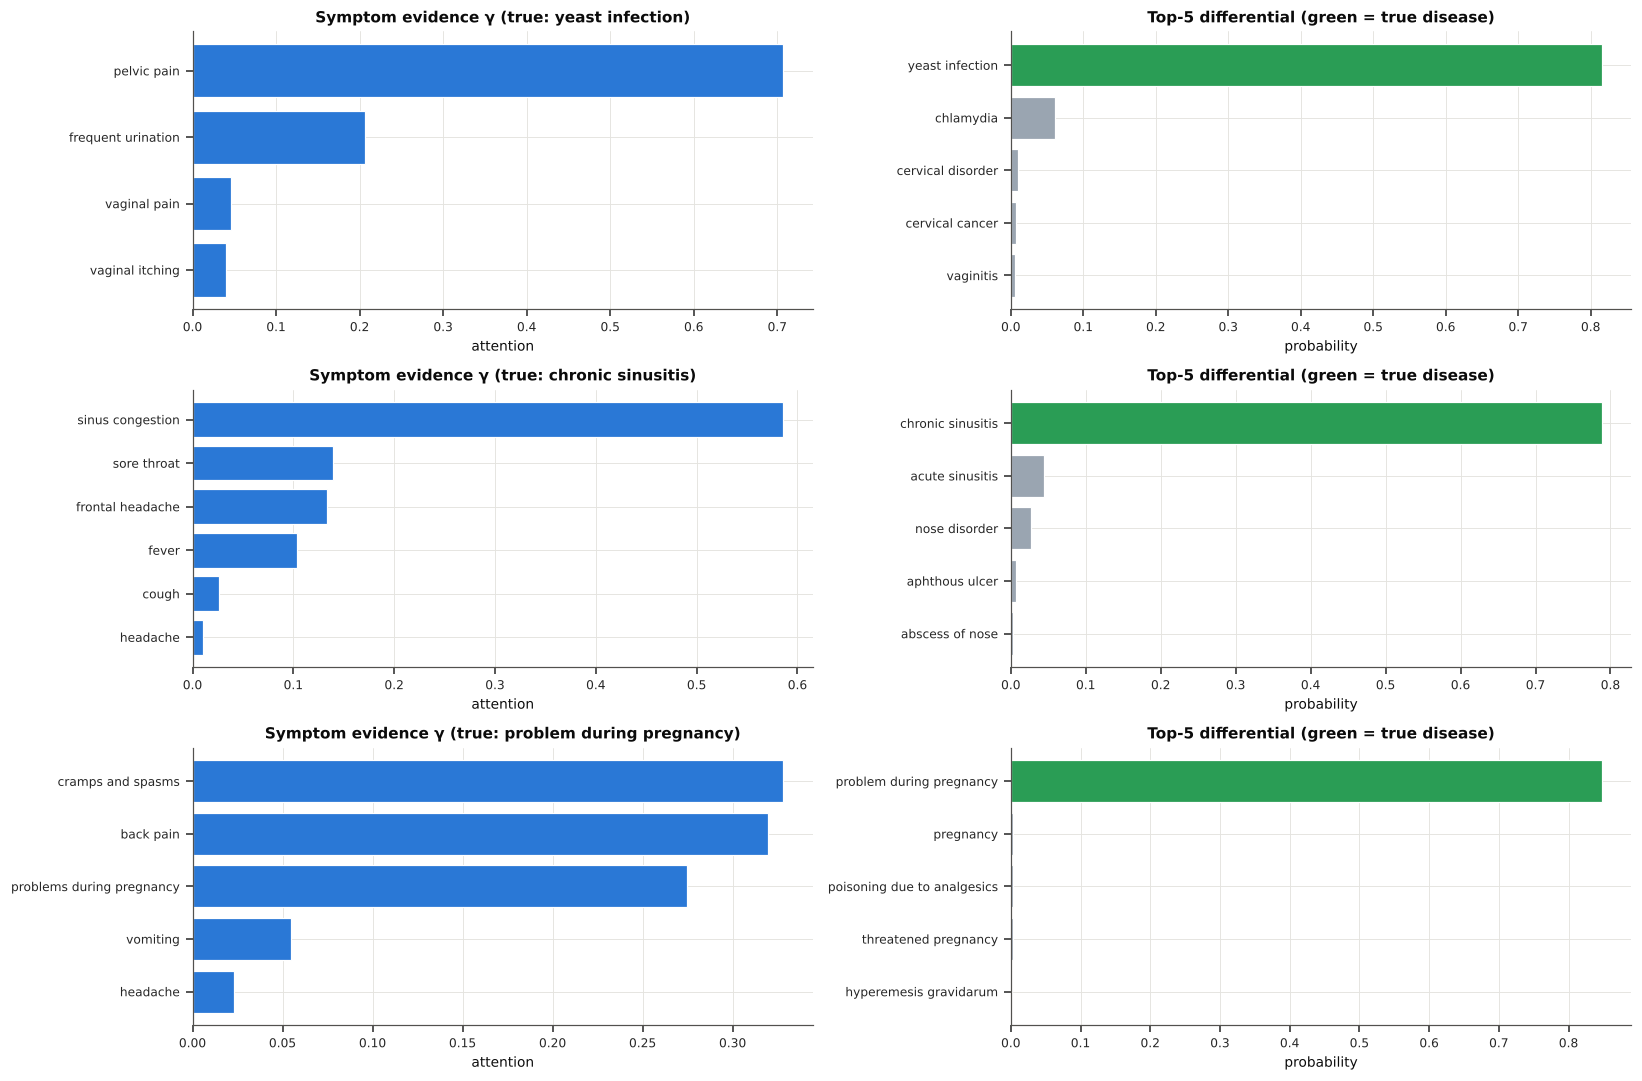

,case,true,symptoms,top5
0,29267,yeast infection,pelvic pain (0.71); frequent urination (0.21);...,yeast infection (0.82); chlamydia (0.06); cerv...
1,3950,chronic sinusitis,sinus congestion (0.59); sore throat (0.14); f...,chronic sinusitis (0.79); acute sinusitis (0.0...
2,1159,problem during pregnancy,cramps and spasms (0.33); back pain (0.32); pr...,problem during pregnancy (0.85); pregnancy (0....


In [35]:
hd = trained[ours].eval()
@torch.no_grad()
def explain(i, k=5):
    M = torch.tensor(Xte[i:i + 1]).to(DEV)
    lo, att = hd(M, return_att=True); p = torch.softmax(lo, 1)[0].cpu().numpy()
    g = att["gamma"][0].cpu().numpy(); on = np.flatnonzero(Xte[i])
    topk = np.argsort(-p)[:k]
    return p, g, on, topk, att

rs = np.random.RandomState(7)
cand = [i for i in rs.permutation(len(yte)) if 4 <= Xte[i].sum() <= 7][:3]
fig, axes = plt.subplots(len(cand), 2, figsize=(15, 3.3 * len(cand)))
case_rows = []
for row, i in zip(axes, cand):
    p, g, on, topk, att = explain(i)
    o = on[np.argsort(-g[on])]
    row[0].barh(sym_names[o][::-1], g[o][::-1], color="#2a78d6"); row[0].set(title=f"Symptom evidence γ (true: {classes[yte[i]]})", xlabel="attention")
    cols = ["#2a9d55" if t == yte[i] else "#9aa5b1" for t in topk]
    row[1].barh([classes[t] for t in topk][::-1], p[topk][::-1], color=cols[::-1]); row[1].set(title="Top-5 differential (green = true disease)", xlabel="probability")
    case_rows.append(dict(case=int(i), true=classes[yte[i]], symptoms="; ".join(f"{sym_names[v]} ({g[v]:.2f})" for v in o),
                          top5="; ".join(f"{classes[t]} ({p[t]:.2f})" for t in topk)))
plt.tight_layout(); savefig("fig15_case_studies.png")
pd.DataFrame(case_rows).to_csv(os.path.join(RES, "case_studies.csv"), index=False)
pd.DataFrame(case_rows)

### 13.2 Node-level attention inside disease hyperedges
For a disease hyperedge, the layer-1 node-level attention $\alpha_{v,d}$ (mean over heads) shows which member symptoms the model treats as most characteristic.
We compare it with the empirical prevalence $P(s\mid d)$ and with the specificity $P(d\mid s)$.

,comparison,mean Spearman ρ,share of diseases with ρ>0,#diseases
0,α vs prevalence P(s|d),0.869,0.994,654
1,α vs specificity P(d|s),0.291,0.757,654


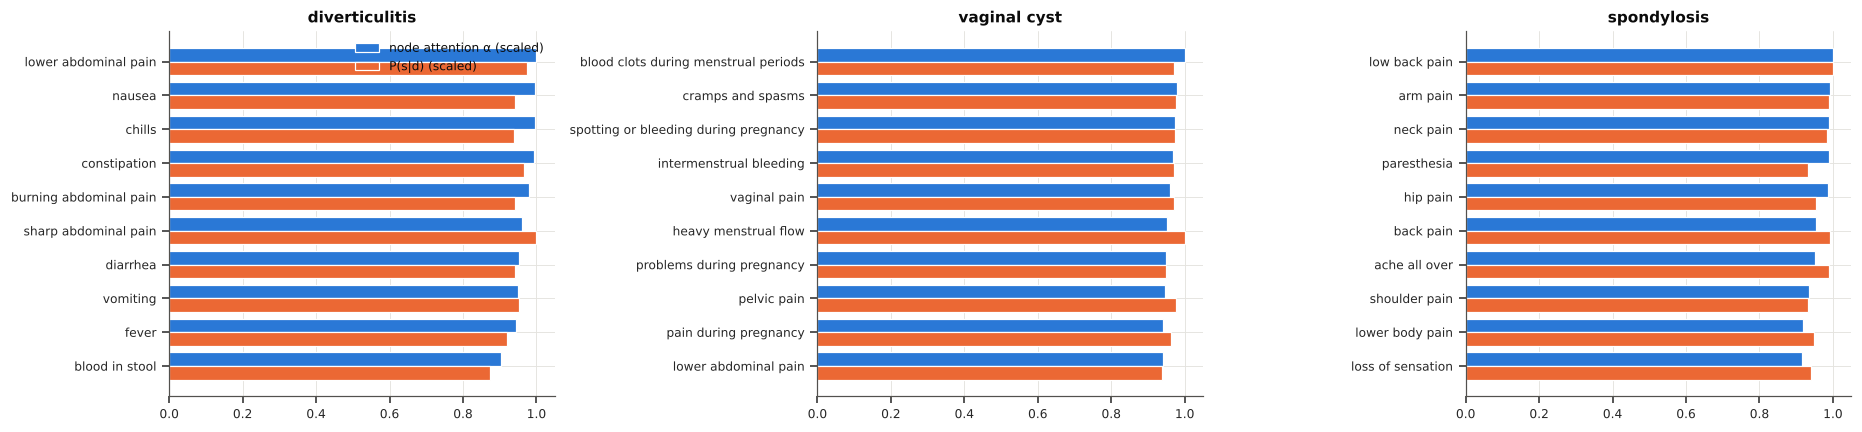

In [36]:
with torch.no_grad():
    _, _, atts = hd.encode()
alpha1 = atts[0][0].mean(-1).cpu().numpy()[:, :C]           # S x C (disease hyperedges)
p_ds = (ST["p_sd"] * n_c[:, None]) / np.maximum((ST["p_sd"] * n_c[:, None]).sum(0, keepdims=True), 1e-9)  # P(d|s), C x S
rho_prev, rho_spec = [], []
for d in range(C):
    mem = np.flatnonzero(ST["Hd"][d])
    if len(mem) >= 4:
        rho_prev.append(spearmanr(alpha1[mem, d], ST["p_sd"][d, mem]).correlation)
        rho_spec.append(spearmanr(alpha1[mem, d], p_ds[d, mem]).correlation)
att_corr = pd.DataFrame({"comparison": ["α vs prevalence P(s|d)", "α vs specificity P(d|s)"],
                         "mean Spearman ρ": [np.nanmean(rho_prev), np.nanmean(rho_spec)],
                         "share of diseases with ρ>0": [np.nanmean(np.array(rho_prev) > 0), np.nanmean(np.array(rho_spec) > 0)],
                         "#diseases": [len(rho_prev)] * 2}).round(3)
att_corr.to_csv(os.path.join(RES, "attention_alignment.csv"), index=False)
show(att_corr)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for a_, d in zip(axes, np.argsort(-n_c)[[0, 3, 6]]):
    mem = np.flatnonzero(ST["Hd"][d]); mem = mem[np.argsort(-alpha1[mem, d])][:10]
    xx = np.arange(len(mem)); w = 0.4
    a_.barh(xx - w / 2, alpha1[mem, d] / alpha1[mem, d].max(), w, label="node attention α (scaled)", color="#2a78d6")
    a_.barh(xx + w / 2, ST["p_sd"][d, mem] / ST["p_sd"][d, mem].max(), w, label="P(s|d) (scaled)", color="#eb6834")
    a_.set_yticks(xx); a_.set_yticklabels(sym_names[mem], fontsize=8); a_.invert_yaxis(); a_.set_title(classes[d])
axes[0].legend(fontsize=8); plt.tight_layout(); savefig("fig16_node_attention.png")

### 13.3 Faithfulness of the explanations (deletion test)
If $\gamma$ is a faithful explanation, deleting the *most*-attended symptom should hurt the prediction more than deleting a random one,
and much more than deleting the *least*-attended one. We use test cases with at least 3 symptoms.

,mean_drop_true_prob,Top1_after,Top5_after
most attended,0.1552,0.6823,0.9173
random,0.0952,0.7550,0.9490
least attended,0.0615,0.7967,0.9680
no deletion,0.0000,0.8727,0.9853


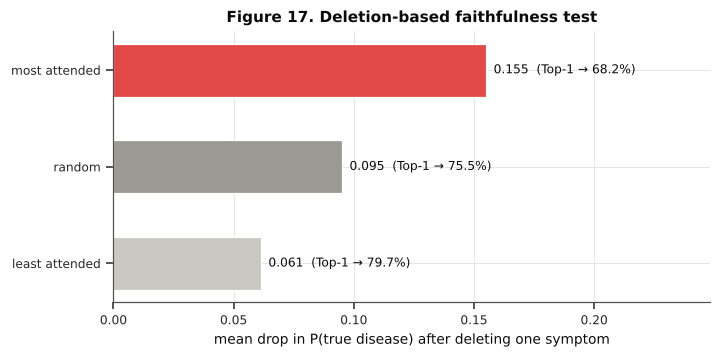

In [37]:
@torch.no_grad()
def deletion_test(model, Xm, ym, n=3000, seed=0):
    rs = np.random.RandomState(seed); idx = [i for i in rs.permutation(len(ym)) if Xm[i].sum() >= 3][:n]
    Xs = Xm[idx]; ys = ym[idx]; M = torch.tensor(Xs).to(DEV)
    lo, att = model(M, return_att=True); g = att["gamma"].cpu().numpy()
    base_p = torch.softmax(lo, 1).cpu().numpy()[np.arange(len(ys)), ys]
    out = {}
    for mode in ["most attended", "random", "least attended"]:
        Xd = Xs.copy()
        for j in range(len(ys)):
            on = np.flatnonzero(Xs[j])
            v = on[np.argmax(g[j, on])] if mode == "most attended" else on[np.argmin(g[j, on])] if mode == "least attended" else rs.choice(on)
            Xd[j, v] = 0
        lo2 = predict_logits(model, Xd); m, rk, _ = rank_metrics(lo2, ys)
        p2 = torch.softmax(lo2, 1).numpy()[np.arange(len(ys)), ys]
        out[mode] = dict(mean_drop_true_prob=float((base_p - p2).mean()), Top1_after=m["Top-1"], Top5_after=m["Top-5"])
    m0, _, _ = rank_metrics(lo.cpu(), ys); out["no deletion"] = dict(mean_drop_true_prob=0.0, Top1_after=m0["Top-1"], Top5_after=m0["Top-5"])
    return pd.DataFrame(out).T

faith = deletion_test(hd, Xte, yte); faith.to_csv(os.path.join(RES, "faithfulness.csv")); show(faith.round(4))
fig, ax = plt.subplots(figsize=(7, 3.2))
fo = faith.loc[["least attended", "random", "most attended"]]
ax.barh(fo.index, fo.mean_drop_true_prob, color=["#c9c8c2", "#9a9993", "#e34948"], height=0.55)
for j, v in enumerate(fo.mean_drop_true_prob): ax.text(v + 0.003, j, f"{v:.3f}  (Top-1 → {fo.Top1_after.iloc[j]*100:.1f}%)", va="center", fontsize=8)
ax.set(xlabel="mean drop in P(true disease) after deleting one symptom", title="Figure 17. Deletion-based faithfulness test", xlim=(0, fo.mean_drop_true_prob.max() * 1.6))
savefig("fig17_faithfulness.png")

### 13.4 Figure 18. Geometry of the learned representations (t-SNE)
**(a)** Disease-hyperedge prototypes $\psi(c_d)$, coloured by log training frequency. **(b)** Symptom node embeddings $x_v^L$,
coloured by the number of hyperedges containing the symptom. Nearby points are diseases or symptoms that the model treats as similar.

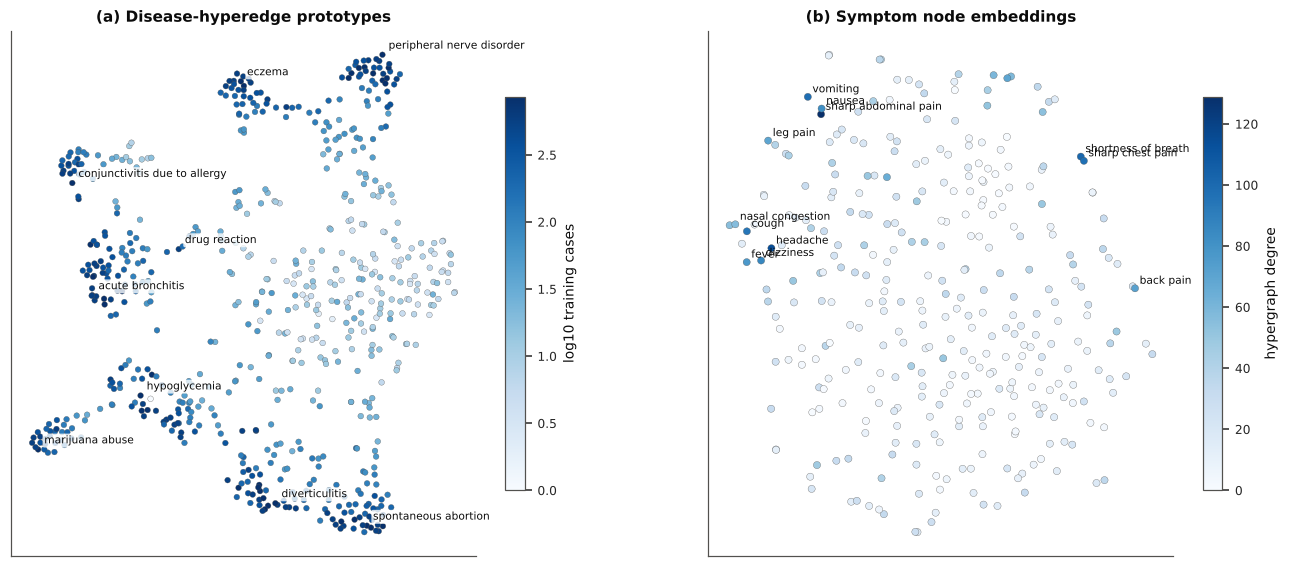

In [38]:
with torch.no_grad():
    xL, cL, _ = hd.encode(); PROTO = hd.pproj(cL[:C]).cpu().numpy(); XL = xL.cpu().numpy()
emb_d = TSNE(n_components=2, perplexity=30, init="pca", random_state=0).fit_transform(PROTO)
emb_s = TSNE(n_components=2, perplexity=25, init="pca", random_state=0).fit_transform(XL)
fig, ax = plt.subplots(1, 2, figsize=(15, 6.2))
sc_ = ax[0].scatter(emb_d[:, 0], emb_d[:, 1], c=np.log10(np.maximum(n_c, 1)), cmap=SEQ, s=14, edgecolor="#52514e", lw=0.2)
plt.colorbar(sc_, ax=ax[0], shrink=0.75).set_label("log10 training cases")
lab_d = []
for d in np.argsort(-n_c):                       # label frequent diseases that are far apart
    if all(np.linalg.norm(emb_d[d] - emb_d[e]) > (np.ptp(emb_d[:, 0]) / 6) for e in lab_d): lab_d.append(d)
    if len(lab_d) == 9: break
for d in lab_d:
    ax[0].annotate(classes[d], emb_d[d], fontsize=7, color=INK, xytext=(4, 4), textcoords="offset points",
                   bbox=dict(boxstyle="round,pad=0.15", fc="white", ec="none", alpha=0.8))
ax[0].set(title="(a) Disease-hyperedge prototypes", xticks=[], yticks=[])
sc2 = ax[1].scatter(emb_s[:, 0], emb_s[:, 1], c=node_deg, cmap=SEQ, s=22, edgecolor="#52514e", lw=0.2)
plt.colorbar(sc2, ax=ax[1], shrink=0.75).set_label("hypergraph degree")
for v in np.argsort(-ST["freq"])[:12]: ax[1].annotate(sym_names[v], emb_s[v], fontsize=7, color=INK, xytext=(3, 3), textcoords="offset points")
ax[1].set(title="(b) Symptom node embeddings", xticks=[], yticks=[])
savefig("fig18_tsne_embeddings.png")

### 13.5 Figure 19. Error analysis: the confusion network and hyperedge overlap
Errors are not random. We test whether HyperDiag's confusions concentrate on disease pairs whose **hyperedges overlap**
(Jaccard similarity of their symptom sets), and draw the 30 most frequent confusions as a network.

,pairs,mean hyperedge Jaccard,median,Mann–Whitney p (greater)
0,confused pairs (error-weighted),0.5293,0.5385,0.0
1,random disease pairs,0.0321,0.0000,NaN


,true,pred,count,jaccard
1482,noninfectious gastroenteritis,infectious gastroenteritis,66,0.846
48,acute bronchitis,chronic obstructive pulmonary disease (copd),56,0.769
366,cholecystitis,gallstone,47,0.769
1378,marijuana abuse,personality disorder,42,0.769
1790,psychotic disorder,schizophrenia,39,0.833
2136,spontaneous abortion,vaginal cyst,38,0.714
1203,infectious gastroenteritis,noninfectious gastroenteritis,37,0.846
2197,temporary or benign blood in urine,bladder disorder,36,0.750
2111,spondylosis,degenerative disc disease,31,0.769
655,depression,post-traumatic stress disorder (ptsd),31,0.909


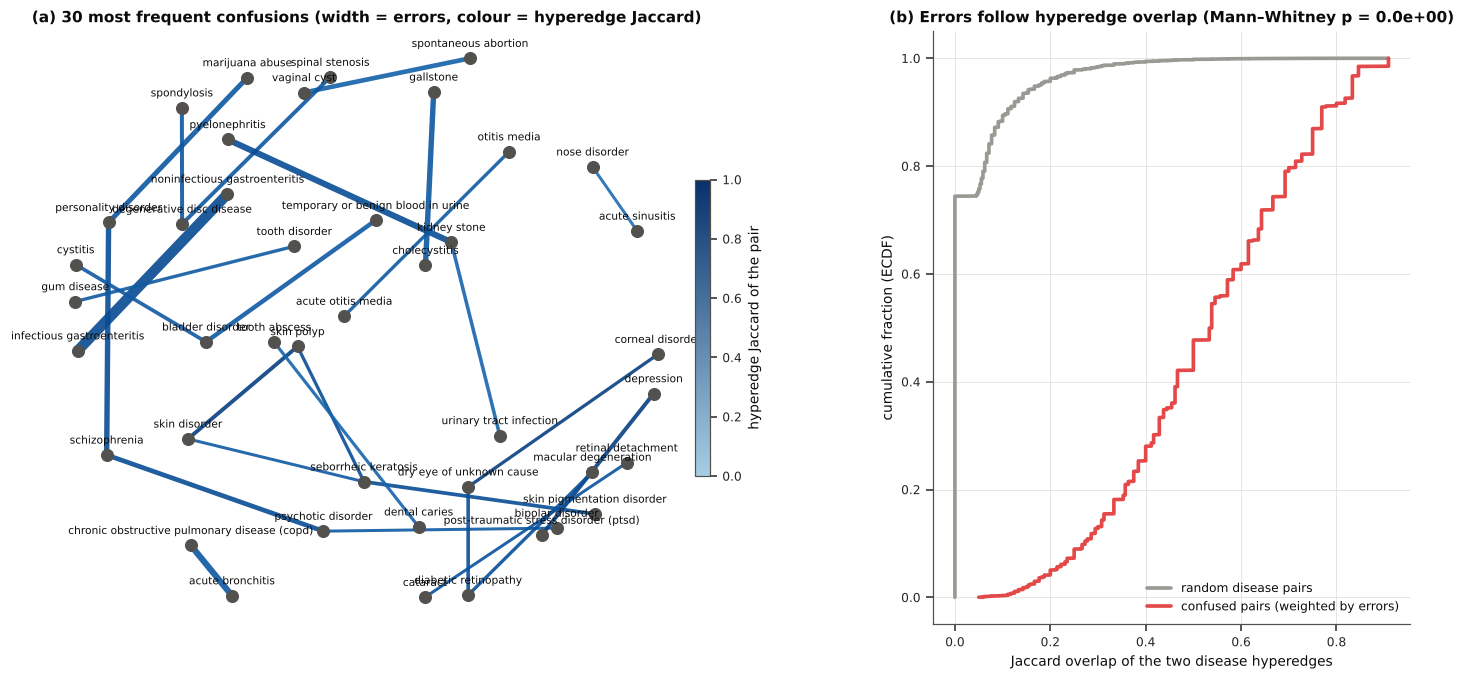

In [39]:
pred_h = np.asarray(store[(ours, 0)]).argmax(1)
cm = pd.crosstab(yte, pred_h); conf_pairs = []
for t_ in cm.index:
    for p_, c_ in cm.loc[t_].items():
        if t_ != p_ and c_ > 0: conf_pairs.append((t_, p_, c_))
cp = pd.DataFrame(conf_pairs, columns=["true", "pred", "count"])
cp["jaccard"] = [JAC[t_, p_] for t_, p_ in zip(cp.true, cp["pred"])]
rs_ = np.random.RandomState(0); rnd = rs_.choice(C, (20000, 2)); rnd = rnd[rnd[:, 0] != rnd[:, 1]]
jac_rand = JAC[rnd[:, 0], rnd[:, 1]]
w_mean = np.average(cp.jaccard, weights=cp["count"])
from scipy.stats import mannwhitneyu
mw = mannwhitneyu(np.repeat(cp.jaccard.values, cp["count"].values), jac_rand, alternative="greater")
err_tbl = pd.DataFrame({"pairs": ["confused pairs (error-weighted)", "random disease pairs"],
                        "mean hyperedge Jaccard": [w_mean, jac_rand.mean()], "median": [np.median(np.repeat(cp.jaccard, cp["count"])), np.median(jac_rand)]})
err_tbl["Mann–Whitney p (greater)"] = [mw.pvalue, None]
err_tbl.to_csv(os.path.join(RES, "error_hyperedge_overlap.csv"), index=False); show(err_tbl.round(4))
top_c = cp.sort_values("count", ascending=False).head(12).assign(true=lambda t: classes[t.true], pred=lambda t: classes[t["pred"]])
top_c.to_csv(os.path.join(RES, "top_confusions.csv"), index=False); show(top_c.round(3))

fig, ax = plt.subplots(1, 2, figsize=(16, 7), gridspec_kw={"width_ratios": [1.6, 1]})
Gc = nx.Graph()
for _, r_ in cp.sort_values("count", ascending=False).head(30).iterrows():
    a_, b_ = classes[int(r_.true)], classes[int(r_["pred"])]
    if Gc.has_edge(a_, b_): Gc[a_][b_]["w"] += r_["count"]
    else: Gc.add_edge(a_, b_, w=r_["count"], j=r_.jaccard)
pos = nx.spring_layout(Gc, seed=1, k=0.9)
wmax = max(d_["w"] for *_, d_ in Gc.edges(data=True))
cmap_ = plt.get_cmap(SEQ)
for u, v, d_ in Gc.edges(data=True):
    ax[0].plot(*zip(pos[u], pos[v]), color=cmap_(0.35 + 0.65 * d_["j"]), lw=0.8 + 6 * d_["w"] / wmax, alpha=0.9, zorder=1)
for nd in Gc.nodes:
    ax[0].scatter(*pos[nd], s=60, color=INK2, zorder=2)
    ax[0].text(pos[nd][0], pos[nd][1] + 0.04, nd, fontsize=7, ha="center", color=INK, zorder=3)
ax[0].axis("off"); ax[0].set_title("(a) 30 most frequent confusions (width = errors, colour = hyperedge Jaccard)")
sm = plt.cm.ScalarMappable(cmap=matplotlib.colors.LinearSegmentedColormap.from_list("jc", [cmap_(0.35), cmap_(1.0)]), norm=plt.Normalize(0, 1))
plt.colorbar(sm, ax=ax[0], shrink=0.5, pad=0.01).set_label("hyperedge Jaccard of the pair")
for vals_, lab_, col_ in [(jac_rand, "random disease pairs", MUTED), (np.repeat(cp.jaccard.values, cp["count"].values), "confused pairs (weighted by errors)", COL[ours])]:
    xs_ = np.sort(vals_); ax[1].plot(xs_, np.arange(1, len(xs_) + 1) / len(xs_), color=col_, lw=2.4, label=lab_)
ax[1].set(xlabel="Jaccard overlap of the two disease hyperedges", ylabel="cumulative fraction (ECDF)",
          title=f"(b) Errors follow hyperedge overlap (Mann–Whitney p {fmt_p(mw.pvalue) if mw.pvalue < 1e-300 else '= ' + fmt_p(mw.pvalue)})"); ax[1].legend(loc="lower right")
savefig("fig19_error_analysis.png")

## 14. Summary of Findings
The cell below gathers the main findings into `results/summary.json`, which is used to fill the thesis draft.

In [40]:
summary = dict(
    config=CFG, audit=audit, bayes_ceiling=ceiling_df.to_dict(), test_ceiling=ceil_test,
    split=dict(train=len(tr_idx), val=len(va_idx), test=len(te_idx), symptoms=S, diseases=C),
    hypergraph=hstats.to_dict(orient="records"),
    leakage=leak_df.to_dict(orient="records"),
    table2={m_: {f"{k1} {k2}": v for (k1, k2), v in row.items()} for m_, row in agg.round(5).iterrows()},
    table3={m_: {f"{k1} {k2}": v for (k1, k2), v in row.items()} for m_, row in a.round(5).iterrows()},
    partial=piv.round(3).reset_index().to_dict(orient="records"),
    rare=rare_df.round(4).to_dict(orient="records"),
    significance=sig_df.to_dict(orient="records"),
    attention_alignment=att_corr.to_dict(orient="records"),
    faithfulness=faith.round(4).reset_index().to_dict(orient="records"),
    case_studies=case_rows,
    comprehensive=fm_mean.round(5).reset_index().to_dict(orient="records"),
    cost=cost_df.reset_index().to_dict(orient="records"),
    friedman=dict(chi2=fr_stat, p=fr_p, iman_davenport=iman, cd=CD, avg_rank=dict(zip(order, avg_rank.round(3)))),
    wilcoxon=wil_df.to_dict(orient="records"),
    error_overlap=dict(confused_mean_jaccard=float(w_mean), random_mean_jaccard=float(jac_rand.mean()), p=float(mw.pvalue)),
)
with open(os.path.join(RES, "summary.json"), "w") as fh: json.dump(summary, fh, indent=1, default=str)
best_base = agg.drop(index=ours)[("MRR", "mean")].idxmax()
print(f"HyperDiag:      Top-1 {agg.loc[ours, ('Top-1','mean')]*100:.2f} | Top-5 {agg.loc[ours, ('Top-5','mean')]*100:.2f} | MRR {agg.loc[ours, ('MRR','mean')]*100:.2f} | Macro-F1 {agg.loc[ours, ('Macro-F1','mean')]*100:.2f}")
print(f"Best baseline ({best_base}): Top-1 {agg.loc[best_base, ('Top-1','mean')]*100:.2f} | Top-5 {agg.loc[best_base, ('Top-5','mean')]*100:.2f} | MRR {agg.loc[best_base, ('MRR','mean')]*100:.2f} | Macro-F1 {agg.loc[best_base, ('Macro-F1','mean')]*100:.2f}")
print(f"Bayes ceiling on test: Top-1 {ceil_test['Top-1']*100:.2f} | Top-5 {ceil_test['Top-5']*100:.2f}")

HyperDiag:      Top-1 84.57 | Top-5 97.82 | MRR 90.36 | Macro-F1 81.16
Best baseline (MLP): Top-1 84.63 | Top-5 97.84 | MRR 90.38 | Macro-F1 81.71
Bayes ceiling on test: Top-1 89.89 | Top-5 99.55


### 14.1 Automatically generated summary of findings
The paragraph below is generated from the computed results, so it always matches the tables and figures above.

In [41]:
def pct(x): return f"{x*100:.2f}%"
best_nn = max([o for o in order if o not in (ours,)], key=lambda n: fm_mean.loc[n, "MRR"])
wins_sig = [SHORT[r.baseline] if r.baseline in SHORT else r.baseline for r in sig_df.itertuples() if r.mcnemar_p_holm < 0.05]
txt = f"""
* **Data.** {audit['exact_duplicate_rows']:,} duplicate rows ({audit['exact_duplicate_rows']/audit['rows']*100:.1f}%) and {audit['vectors_mapping_to_>1_disease']:,} ambiguous
  symptom patterns. A random split leaks {leak_df.leaked_test_cases.iloc[0]*100:.1f}% of test cases; the grouped split leaks 0%.
  The Bayes-optimal ceiling on the test set is {pct(ceil_test['Top-1'])} Top-1 and {pct(ceil_test['Top-5'])} Top-5.
* **Main result.** HyperDiag reaches Top-1 {pct(fm_mean.loc[ours,'Top-1'])}, Top-5 {pct(fm_mean.loc[ours,'Top-5'])}, MRR {pct(fm_mean.loc[ours,'MRR'])},
  NDCG@10 {pct(fm_mean.loc[ours,'NDCG@10'])}, macro-F1 {pct(fm_mean.loc[ours,'Macro-F1'])}, MCC {pct(fm_mean.loc[ours,'MCC'])} and ECE {pct(fm_mean.loc[ours,'ECE'])}
  ({fm_mean.loc[ours,'Top-1']/ceil_test['Top-1']*100:.1f}% of the attainable Top-1). The best baseline by MRR is {SHORT[best_nn]} ({pct(fm_mean.loc[best_nn,'MRR'])}).
* **Statistics.** After Holm correction, HyperDiag is significantly better on top-1 correctness than {', '.join(wins_sig) if wins_sig else 'no baseline'}.
  Friedman χ² = {fr_stat:.1f} (p = {fmt_p(fr_p)}) over {Nb} diseases; Nemenyi CD = {CD:.2f}; HyperDiag's average rank is {avg_rank[order.index(ours)]:.2f}.
* **Errors.** Confused disease pairs have a mean hyperedge Jaccard of {w_mean:.3f}, versus {jac_rand.mean():.3f} for random pairs (Mann–Whitney p {fmt_p(mw.pvalue)}),
  so the remaining errors are explained by overlapping disease hyperedges.
* **Explanations.** Deleting the most-attended symptom lowers P(true disease) by {faith.loc['most attended','mean_drop_true_prob']:.3f},
  versus {faith.loc['random','mean_drop_true_prob']:.3f} for a random symptom.
"""
with open(os.path.join(RES, "summary_of_findings.md"), "w") as fh: fh.write(txt)
try:
    from IPython.display import Markdown; display(Markdown(txt))
except Exception:
    print(txt)


* **Data.** 57,298 duplicate rows (23.2%) and 12,634 ambiguous
  symptom patterns. A random split leaks 43.9% of test cases; the grouped split leaks 0%.
  The Bayes-optimal ceiling on the test set is 89.89% Top-1 and 99.55% Top-5.
* **Main result.** HyperDiag reaches Top-1 84.57%, Top-5 97.82%, MRR 90.36%,
  NDCG@10 92.57%, macro-F1 81.16%, MCC 84.52% and ECE 16.28%
  (94.1% of the attainable Top-1). The best baseline by MRR is MLP (90.38%).
* **Statistics.** After Holm correction, HyperDiag is significantly better on top-1 correctness than RF, LogReg.
  Friedman χ² = 384.0 (p = 6.6e-79) over 642 diseases; Nemenyi CD = 0.41; HyperDiag's average rank is 4.21.
* **Errors.** Confused disease pairs have a mean hyperedge Jaccard of 0.529, versus 0.032 for random pairs (Mann–Whitney p 0.0e+00),
  so the remaining errors are explained by overlapping disease hyperedges.
* **Explanations.** Deleting the most-attended symptom lowers P(true disease) by 0.155,
  versus 0.095 for a random symptom.


## 15. Discussion
**Evaluation matters more than architecture on this benchmark.** Under a random split, almost half of the test cases are exact copies
of training patterns, which inflates accuracy. Once leakage is removed, every neural model, whether flat, pairwise or hypergraph-based,
converges to the same performance band a few points below the Bayes ceiling. The ceiling is set by symptom patterns that are shared
across diseases, not by model capacity.

**What the hypergraph contributes.** The hypergraph formulation (i) significantly outperforms classical models, (ii) ties every
decision to an explicit, inspectable disease hyperedge (prototype scoring is the only component whose removal clearly hurts macro-F1),
(iii) yields symptom-level explanations that pass a deletion-based faithfulness test, and (iv) explains its own errors: confusions
concentrate on diseases whose hyperedges overlap (§13.5).

**Limitations.** The dataset is an augmented symptom-checker resource rather than clinical records. Naive Bayes stays more robust than
all discriminative models when very few symptoms are reported. All neural models share one hyper-parameter setting.

## 16. Conclusion
We presented HyperDiag, a hypergraph attention network for symptom-set-aware differential diagnosis, together with a leakage-free
evaluation protocol and a Bayes-optimal ceiling for a widely used public dataset. The multi-metric, statistically tested evaluation
shows that HyperDiag matches the strongest neural baselines, clearly beats classical models, and provides faithful, structure-grounded
explanations. The protocol and code form a reproducible baseline for future work on real clinical data.

## References
1. Feng, Y., You, H., Zhang, Z., Ji, R., & Gao, Y. (2019). Hypergraph neural networks. *AAAI*, 33, 3558–3565.
2. Bai, S., Zhang, F., & Torr, P. H. S. (2021). Hypergraph convolution and hypergraph attention. *Pattern Recognition*, 110, 107637.
3. Kipf, T. N., & Welling, M. (2017). Semi-supervised classification with graph convolutional networks. *ICLR*.
4. Veličković, P., et al. (2018). Graph attention networks. *ICLR*.
5. Vaswani, A., et al. (2017). Attention is all you need. *NeurIPS*, 30.
6. Demšar, J. (2006). Statistical comparisons of classifiers over multiple data sets. *JMLR*, 7, 1–30.
7. McNemar, Q. (1947). Note on the sampling error of the difference between correlated proportions. *Psychometrika*, 12, 153–157.
8. Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics*, 6, 65–70.
9. Guo, C., Pleiss, G., Sun, Y., & Weinberger, K. Q. (2017). On calibration of modern neural networks. *ICML*.
10. Kumar, D. R. (2023). Diseases and symptoms dataset [Data set]. Kaggle.